# UNITASK + BASLINE MODELS 

## DSM SPATIAL CROSS-VALIDATION EXPERIMENT ANALYSIS

With only one simple model architecture 

In [26]:
import os
import re
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")



In [27]:



# ============================================================
# 1. CONFIGURATION
# ============================================================

REGION = 'all'
MODEL= 'MLP'  # Change this to the model you want to visualize
INPUT_DIR = f"../Results/evaluation_on_bestconfigs/{REGION}/{MODEL}"

OUTPUT_DIR = fr"cv_visualizations/{REGION}/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

THRESHOLDS_KM = [
    5, 10, 20, 30, 50, 100
]

PROPERTIES = [
    "pH",
    "CE",
    "CEC",
    "OM",
    "A%",
    "L%",
    "S%"
]

CV_METHODS = [
    "random",
    "block",
    "sp1",
    "sp2",
    "sp"
]

METRIC_OF_CHOICE= "RMSE"

# ============================================================
# SPATIAL CROSS-VALIDATION VISUALIZATION PIPELINE
# ============================================================
#
# Output structure:
#
# cv_visualizations/
# ├── RandomForest/
# │   ├── 01_curves/
# │   ├── 02_heatmaps/
# │   ├── 03_random_comparison/
# │
# ├── MLP/
# │   └── ...
# │
# └── CNN/
#     └── ...
#
# ============================================================


# ============================================================
# 2. CREATE OUTPUT DIRECTORY STRUCTURE
# ============================================================

def create_cv_comparison_structure(model_name):
    base = os.path.join(
        OUTPUT_DIR,
        model_name,
        "03_cv_comparison"
    )

    folders = [
        "method_ranking",
        "threshold_sensitivity",
        "performance_variability",
        "relative_to_best"
    ]

    for folder in folders:
        os.makedirs(
            os.path.join(base, folder),
            exist_ok=True
        )

def create_output_structure(model_name):
    """
    Create the complete visualization folder structure
    for one model.
    """

    model_dir = os.path.join(
        OUTPUT_DIR,
        model_name
    )

    folders = [

        # ----------------------------------------------------
        # Curves
        # ----------------------------------------------------
        os.path.join(
            model_dir,
            "01_curves",
            "RMSE_vs_threshold"
        ),

        os.path.join(
            model_dir,
            "01_curves",
            "MAE_vs_threshold"
        ),

        os.path.join(
            model_dir,
            "01_curves",
            "R2_vs_threshold"
        ),

        # ----------------------------------------------------
        # Heatmaps
        # ----------------------------------------------------
        os.path.join(
            model_dir,
            "02_heatmaps",
            "RMSE"
        ),

        os.path.join(
            model_dir,
            "02_heatmaps",
            "MAE"
        ),

        os.path.join(
            model_dir,
            "02_heatmaps",
            "R2"
        ),

        os.path.join(
            model_dir,
            "02_heatmaps",
            "NRMSE"
        ),

        # ----------------------------------------------------
        # Comparison with Random CV and SP2 
        # ----------------------------------------------------
        
    ]

    for folder in folders:
        os.makedirs(folder, exist_ok=True)
    create_cv_comparison_structure(model_name)
    
    return model_dir


# ============================================================
# 3. LOAD EXPERIMENT FILES
# ============================================================

def load_experiment_data(input_dir):
    """
    Load all spatial-CV experiment CSV files.

    Expected filename:
        experiments_RandomForest_block_k5_100000.csv

    Meaning:
        RandomForest = model
        block        = CV method
        k5           = 5 folds
        100000       = 100 km

    The CV method is ALWAYS taken from the filename.
    """

    # pattern = (
    #     r"experiments_"
    #     r"(?P<model>[^_]+)_"
    #     r"(?P<cv_method>[^_]+)_"
    #     r"k(?P<k>\d+)_"
    #     r"(?P<threshold>\d+)"
    #     r"_2d_dm_new.csv$"
    # )

    pattern = (
    r"experiments_"
    r"(?P<model>[^_]+)_"
    r"(?P<cv_method>[^_]+)_"
    r"k(?P<k>\d+)"
    r"(?:_(?P<threshold>\d+))?"
    r"_2d_dm_new.csv$"
    )

    files = glob.glob(
        os.path.join(
            input_dir,
            "experiments_*.csv"
        )
    )

    if not files:
        raise ValueError(
            f"No experiment files found in:\n{input_dir}"
        )

    all_data = []

    for file in files:

        filename = os.path.basename(file)

        match = re.match(
            pattern,
            filename
        )

        if not match:

            print(
                f"WARNING: filename not recognized:\n"
                f"  {filename}"
            )

            continue

        metadata = match.groupdict()

        model = metadata["model"]
        cv_method = metadata["cv_method"]
        k = int(metadata["k"])
    
        if metadata["threshold"] is not None:
            threshold_m = int(metadata["threshold"])
            threshold_km = threshold_m / 1000
        else:
            threshold_m = None
            threshold_km = None

        # ----------------------------------------------------
        # Read CSV
        # ----------------------------------------------------

        df = pd.read_csv(file)

        # ----------------------------------------------------
        # Metadata from filename
        # ----------------------------------------------------
        if 'soil_property' not in df.columns:
            print(
                f"WARNING: 'soil_property' column not found in:\n"
                f"  {filename}"
            )
            df['soil_property'] = df['soil_properties'] if 'soil_properties' in df.columns else None
        model = metadata["model"]

        cv_method = metadata["cv_method"]

        k = int(
            metadata["k"]
        )


        # ----------------------------------------------------
        # IMPORTANT:
        # Overwrite any existing CV information.
        # The filename is the authoritative source.
        # ----------------------------------------------------

        df["model"] = model

        df["cv_method"] = cv_method

        df["k"] = k

        df["threshold_m"] = threshold_m

        df["threshold_km"] = threshold_km

        df["filename"] = filename

        all_data.append(df)

    # --------------------------------------------------------
    # Combine
    # --------------------------------------------------------

    if not all_data:

        raise ValueError(
            "No valid experiment files were found."
        )

    data = pd.concat(
        all_data,
        ignore_index=True
    )

    # --------------------------------------------------------
    # Standardize metric names
    # --------------------------------------------------------

    rename_dict = {
        "rmse": "RMSE",
        "mse": "MSE",
        "r2": "R2",
        "mae": "MAE",
        "time": "Time"
    }

    data = data.rename(
        columns=rename_dict
    )

    # --------------------------------------------------------
    # Clean CV method
    # --------------------------------------------------------

    data["cv_method"] = (
        data["cv_method"]
        .astype(str)
        .str.strip()
    )

    # --------------------------------------------------------
    # Standardize known names
    # --------------------------------------------------------

    cv_mapping = {
        "random": "Random",
        "Random": "Random",

        "block": "blockCV",
        "Block": "blockCV",
        "blockCV": "blockCV",

        "SP1": "SP1",
        "sp1": "SP1",

        "SP2": "SP2",
        "sp2": "SP2",

        "SP": "SP",
        "sp": "SP"
    }

    data["cv_method"] = (
        data["cv_method"]
        .replace(cv_mapping)
    )

    return data

# ============================================================
# 4. BASIC DATA CLEANING
# ============================================================

def prepare_data(df):

    df = df.copy()

    # --------------------------------------------------------
    # Ensure numeric columns
    # --------------------------------------------------------

    numeric_columns = [
        "RMSE",
        "MSE",
        "R2",
        "MAE",
        "Time",
        "threshold_m",
        "threshold_km"
    ]

    for col in numeric_columns:

        if col in df.columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

    # --------------------------------------------------------
    # Standardize model names
    # --------------------------------------------------------

    model_mapping = {
        "RandomForest": "RandomForest",
        "RF": "RandomForest",
        "randomforest": "RandomForest",

        "MLP": "MLP",
        "mlp": "MLP",

        "CNN": "CNN",
        "cnn": "CNN"
    }

    df["model"] = (
        df["model"]
        .replace(model_mapping)
    )

    # --------------------------------------------------------
    # Standardize CV names
    # --------------------------------------------------------

    cv_mapping = {
        "random": "Random",
        "Random": "Random",

        "block": "blockCV",
        "blockCV": "blockCV",

        "SP1": "SP1",
        "SP2": "SP2",
        "SP": "SP"
    }

    df["cv_method"] = (
        df["cv_method"]
        .replace(cv_mapping)
    )

    return df


# ============================================================
# 5. NRMSE
# ============================================================

def add_nrmse(df):
    """
    NRMSE = RMSE / standard deviation of the target.

    The standard deviation is calculated within each
    soil-property/depth group.
    """

    df = df.copy()

    if "RMSE" not in df.columns:
        return df

    if "soil_property" not in df.columns:
        return df

    grouping = [
        "soil_property"
    ]

    if "depth" in df.columns:
        grouping.append("depth")

    # --------------------------------------------------------
    # Estimate target SD from available MSE/RMSE information
    # only if a target SD column does not already exist.
    #
    # If you have the actual target SD in your experiment
    # results, use that instead.
    # --------------------------------------------------------

    if "target_std" in df.columns:

        df["NRMSE"] = (
            df["RMSE"] /
            df["target_std"]
        )

    else:

        print(
            "WARNING: target_std is not available. "
            "NRMSE will not be calculated."
        )

        df["NRMSE"] = np.nan

    return df


# ============================================================
# 6. PREPARE AGGREGATED RESULTS
# ============================================================

def aggregate_results(df):

    grouping = [
        "model",
        "soil_property",
        "cv_method",
        "threshold_km"
    ]

    # --------------------------------------------------------
    # Keep depth separate
    # --------------------------------------------------------

    if "depth" in df.columns:
        grouping.append("depth")

    # --------------------------------------------------------
    # Keep normalization separate
    # --------------------------------------------------------

    if "normalization" in df.columns:
        grouping.append("normalization")

    available_metrics = [
        m for m in [
            "RMSE",
            "MAE",
            "R2",
            "NRMSE"
        ]
        if m in df.columns
    ]

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # This aggregation is appropriate only when repeated rows
    # represent repeated runs / replicates.
    #
    # If rows correspond to different hyperparameter
    # configurations, DO NOT average them.
    # --------------------------------------------------------

    agg_dict = {}

    for metric in available_metrics:
        agg_dict[metric] = "mean"

    if "Time" in df.columns:
        agg_dict["Time"] = "mean"

    result = (
        df.groupby(
            grouping,
            dropna=False
        )
        .agg(agg_dict)
        .reset_index()
    )

    return result


# ============================================================
# 7. CURVE PLOTS
# ============================================================

def plot_metric_vs_threshold(
    df,
    model_name,
    metric
):

    model_df = df[
        df["model"] == model_name
    ].copy()

    if model_df.empty:
        return

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "01_curves",
        f"{metric}_vs_threshold"
    )

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    properties = (
        model_df["soil_property"]
        .dropna()
        .unique()
    )

    for property_name in properties:

        prop_df = model_df[
            model_df["soil_property"]
            == property_name
        ].copy()

        # ----------------------------------------------------
        # Separate figure for each depth
        # ----------------------------------------------------

        depths = (
            prop_df["depth"]
            .dropna()
            .unique()
            if "depth" in prop_df.columns
            else [None]
        )

        for depth in depths:

            if depth is not None:

                plot_df = prop_df[
                    prop_df["depth"] == depth
                ].copy()

            else:

                plot_df = prop_df.copy()

            if plot_df.empty:
                continue

            plt.figure(
                figsize=(10, 6)
            )

            sns.lineplot(
                data=plot_df,
                x="threshold_km",
                y=metric,
                hue="cv_method",
                marker="o",
                linewidth=2
            )

            plt.xlabel(
                "Spatial threshold (km)"
            )

            plt.ylabel(metric)

            plt.title(
                f"{model_name} — "
                f"{property_name} — "
                f"{metric}"
                + (
                    f" — depth {depth}"
                    if depth is not None
                    else ""
                )
            )

            plt.grid(
                alpha=0.25
            )

            plt.tight_layout()

            filename = (
                f"{metric}_vs_threshold_"
                f"{model_name}_"
                f"{property_name}"
            )

            if depth is not None:
                filename += (
                    f"_{str(depth).replace('/', '-')}"
                )

            filename += ".png"

            plt.savefig(
                os.path.join(
                    output_dir,
                    filename
                ),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()


# ============================================================
# 8. HEATMAPS
# ============================================================

def plot_heatmaps(
    df,
    model_name,
    metric
):

    model_df = df[
        df["model"] == model_name
    ].copy()

    if model_df.empty:
        return

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "02_heatmaps",
        metric
    )

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    properties = (
        model_df["soil_property"]
        .dropna()
        .unique()
    )

    for property_name in properties:

        prop_df = model_df[
            model_df["soil_property"]
            == property_name
        ].copy()

        depths = (
            prop_df["depth"]
            .dropna()
            .unique()
            if "depth" in prop_df.columns
            else [None]
        )

        for depth in depths:

            if depth is not None:

                plot_df = prop_df[
                    prop_df["depth"] == depth
                ].copy()

            else:

                plot_df = prop_df.copy()

            if plot_df.empty:
                continue

            pivot = plot_df.pivot_table(
                index="cv_method",
                columns="threshold_km",
                values=metric,
                aggfunc="mean"
            )

            plt.figure(
                figsize=(11, 6)
            )

            sns.heatmap(
                pivot,
                annot=True,
                fmt=".3f",
                cmap="viridis"
            )

            plt.xlabel(
                "Spatial threshold (km)"
            )

            plt.ylabel(
                "CV method"
            )

            plt.title(
                f"{model_name} — "
                f"{property_name} — "
                f"{metric}"
                + (
                    f" — depth {depth}"
                    if depth is not None
                    else ""
                )
            )

            plt.tight_layout()

            filename = (
                f"{metric}_heatmap_"
                f"{model_name}_"
                f"{property_name}"
            )

            if depth is not None:
                filename += (
                    f"_{str(depth).replace('/', '-')}"
                )

            filename += ".png"

            plt.savefig(
                os.path.join(
                    output_dir,
                    filename
                ),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()


# ============================================================
# 9. NRMSE HEATMAP ACROSS PROPERTIES
# ============================================================

def plot_nrmse_heatmap(
    df,
    model_name
):
    """
    Generate NRMSE heatmaps only when valid NRMSE values
    are available.

    NRMSE = RMSE / target_std

    If target_std is not available, the function skips
    NRMSE visualization instead of producing an error.
    """

    # --------------------------------------------------------
    # Check that NRMSE exists
    # --------------------------------------------------------

    if "NRMSE" not in df.columns:

        print(
            f"[{model_name}] NRMSE skipped: "
            "NRMSE column not found."
        )

        return

    # --------------------------------------------------------
    # Check that there are actual numeric values
    # --------------------------------------------------------

    nrmse = pd.to_numeric(
        df["NRMSE"],
        errors="coerce"
    )

    if nrmse.notna().sum() == 0:

        print(
            f"[{model_name}] NRMSE skipped: "
            "all NRMSE values are NaN."
        )

        return

    # --------------------------------------------------------
    # Keep model
    # --------------------------------------------------------

    model_df = df[
        df["model"] == model_name
    ].copy()

    if model_df.empty:
        return

    # --------------------------------------------------------
    # Convert NRMSE to numeric
    # --------------------------------------------------------

    model_df["NRMSE"] = pd.to_numeric(
        model_df["NRMSE"],
        errors="coerce"
    )

    # Remove invalid rows
    model_df = model_df.dropna(
        subset=[
            "NRMSE",
            "soil_property",
            "threshold_km"
        ]
    )

    if model_df.empty:

        print(
            f"[{model_name}] NRMSE skipped: "
            "no valid NRMSE observations."
        )

        return

    # --------------------------------------------------------
    # Output directory
    # --------------------------------------------------------

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "02_heatmaps",
        "NRMSE"
    )

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Depths
    # --------------------------------------------------------

    if "depth" in model_df.columns:

        depths = (
            model_df["depth"]
            .dropna()
            .unique()
        )

    else:

        depths = [None]

    # --------------------------------------------------------
    # Generate heatmap for each depth
    # --------------------------------------------------------

    for depth in depths:

        if depth is not None:

            plot_df = model_df[
                model_df["depth"] == depth
            ].copy()

        else:

            plot_df = model_df.copy()

        if plot_df.empty:
            continue

        # ----------------------------------------------------
        # Pivot
        # ----------------------------------------------------

        pivot = plot_df.pivot_table(
            index="soil_property",
            columns="threshold_km",
            values="NRMSE",
            aggfunc="mean"
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # Don't call seaborn if pivot is empty.
        # ----------------------------------------------------

        if pivot.empty:

            print(
                f"[{model_name}] NRMSE skipped for "
                f"depth {depth}: empty pivot table."
            )

            continue

        if pivot.dropna(
            how="all"
        ).empty:

            print(
                f"[{model_name}] NRMSE skipped for "
                f"depth {depth}: all values are NaN."
            )

            continue

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        plt.figure(
            figsize=(11, 7)
        )

        sns.heatmap(
            pivot,
            annot=True,
            fmt=".3f",
            cmap="viridis"
        )

        plt.xlabel(
            "Spatial threshold (km)"
        )

        plt.ylabel(
            "Soil property"
        )

        title = (
            f"{model_name} — NRMSE"
        )

        if depth is not None:

            title += (
                f" — depth {depth}"
            )

        plt.title(title)

        plt.tight_layout()

        # ----------------------------------------------------
        # Filename
        # ----------------------------------------------------

        filename = (
            f"NRMSE_heatmap_"
            f"{model_name}"
        )

        if depth is not None:

            filename += (
                f"_{str(depth).replace('/', '-')}"
            )

        filename += ".png"

        plt.savefig(
            os.path.join(
                output_dir,
                filename
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.close()

        print(
            f"Saved NRMSE heatmap: {filename}"
        )
# ============================================================
# 10. COMPARISON WITH RANDOM CV
# ============================================================


def plot_threshold_sensitivity(df, model_name, metric="RMSE"):

    model_df = df[
        (df["model"] == model_name) &
        (df["cv_method"].isin(["blockCV", "SP1", "SP"]))
    ].copy()

    model_df = model_df.dropna(
        subset=["threshold_km", metric]
    )

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "03_cv_comparison",
        "threshold_sensitivity"
    )

    os.makedirs(output_dir, exist_ok=True)

    properties = sorted(
        model_df["soil_property"].dropna().unique()
    )

    # ----------------------------------------------------------
    # Metric-specific sensitivity definition
    # ----------------------------------------------------------

    if metric == "R2":

        sensitivity_column = "sensitivity"
        ylabel = r"$\Delta R^2$ from previous threshold"
        sensitivity_type = "absolute"

    elif metric in ["RMSE", "MAE", "MSE"]:

        sensitivity_column = "sensitivity_percent"
        ylabel = f"Change in {metric} from previous threshold (%)"
        sensitivity_type = "percentage"

    else:
        raise ValueError(
            f"Unsupported metric for threshold sensitivity: {metric}"
        )

    # ----------------------------------------------------------
    # Process each property
    # ----------------------------------------------------------

    for property_name in properties:

        prop_df = model_df[
            model_df["soil_property"] == property_name
        ].copy()

        if "depth" in prop_df.columns:
            depths = prop_df["depth"].dropna().unique()
        else:
            depths = [None]

        for depth in depths:

            if depth is not None:
                data = prop_df[
                    prop_df["depth"] == depth
                ].copy()
            else:
                data = prop_df.copy()

            if data.empty:
                continue

            # --------------------------------------------------
            # Sort thresholds
            # --------------------------------------------------

            data = data.sort_values(
                ["cv_method", "threshold_km"]
            )

            # --------------------------------------------------
            # Previous threshold value
            # --------------------------------------------------

            data["previous_metric"] = (
                data
                .groupby("cv_method")[metric]
                .shift(1)
            )

            # --------------------------------------------------
            # Calculate sensitivity
            # --------------------------------------------------

            if sensitivity_type == "percentage":

                data[sensitivity_column] = (
                    (
                        data[metric]
                        - data["previous_metric"]
                    )
                    / data["previous_metric"]
                    * 100
                )

            else:

                # R²:
                #
                # ΔR² = R²(current) - R²(previous)
                #
                data[sensitivity_column] = (
                    data[metric]
                    - data["previous_metric"]
                )

            # --------------------------------------------------
            # Remove first threshold of each CV method
            # because it has no previous threshold
            # --------------------------------------------------

            data = data.dropna(
                subset=[sensitivity_column]
            )

            if data.empty:
                continue

            # --------------------------------------------------
            # Plot
            # --------------------------------------------------

            plt.figure(figsize=(10, 6))

            sns.lineplot(
                data=data,
                x="threshold_km",
                y=sensitivity_column,
                hue="cv_method",
                hue_order=["blockCV", "SP1", "SP"],
                marker="o",
                linewidth=2,
                errorbar=None
            )

            # --------------------------------------------------
            # Zero reference line
            # --------------------------------------------------

            plt.axhline(
                0,
                linestyle="--",
                linewidth=1
            )

            # --------------------------------------------------
            # Labels
            # --------------------------------------------------

            plt.xlabel(
                "Spatial threshold (km)"
            )

            plt.ylabel(
                ylabel
            )

            title = (
                f"{model_name} — {property_name} — "
                f"{metric} threshold sensitivity"
            )

            if depth is not None:
                title += f" — depth {depth}"

            plt.title(title)

            plt.xticks(
                [10, 20, 30, 50, 100, 150, 200]
            )

            plt.grid(alpha=0.25)

            plt.legend(
                title="CV method"
            )

            plt.tight_layout()

            # --------------------------------------------------
            # Save
            # --------------------------------------------------

            filename = (
                f"{metric}_threshold_sensitivity_"
                f"{model_name}_{property_name}"
            )

            if depth is not None:
                filename += (
                    f"_{str(depth).replace('/', '-')}"
                )

            filename += ".png"

            plt.savefig(
                os.path.join(
                    output_dir,
                    filename
                ),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()

def calculate_relative_to_best(df, model_name, metric="RMSE"):

    model_df = df[
        (df["model"] == model_name) &
        (df["cv_method"].isin(["blockCV", "SP1", "SP"]))
    ].copy()

    model_df = model_df.dropna(
        subset=["threshold_km", metric]
    )

    group_cols = [
        "soil_property",
        "depth",
        "cv_method"
    ]

    best_values = (
        model_df
        .groupby(group_cols)[metric]
        .transform("min")
    )

    model_df["relative_to_best"] = (
        (model_df[metric] - best_values)
        / best_values
        * 100
    )

    return model_df

def plot_relative_to_best(df, model_name, metric="RMSE"):

    plot_df = calculate_relative_to_best(
        df,
        model_name,
        metric
    )

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "03_cv_comparison",
        "relative_to_best"
    )

    os.makedirs(output_dir, exist_ok=True)

    properties = sorted(
        plot_df["soil_property"].dropna().unique()
    )

    for property_name in properties:

        prop_df = plot_df[
            plot_df["soil_property"] == property_name
        ]

        depths = prop_df["depth"].dropna().unique()

        for depth in depths:

            data = prop_df[
                prop_df["depth"] == depth
            ].copy()

            if data.empty:
                continue

            plt.figure(figsize=(10, 6))

            sns.lineplot(
                data=data,
                x="threshold_km",
                y="relative_to_best",
                hue="cv_method",
                hue_order=["blockCV", "SP1", "SP"],
                marker="o",
                linewidth=2,
                errorbar=None
            )

            plt.axhline(
                0,
                linestyle="--",
                linewidth=1
            )

            plt.xlabel("Spatial threshold (km)")
            plt.ylabel(
                "RMSE increase relative to best threshold (%)"
            )

            plt.title(
                f"{model_name} — {property_name} — "
                f"Relative RMSE to best threshold — depth {depth}"
            )

            plt.xticks(
                [5, 10, 20, 30, 50, 100, 150, 200]
            )

            plt.grid(alpha=0.25)
            plt.legend(title="CV method")

            plt.tight_layout()

            filename = (
                f"relative_RMSE_to_best_"
                f"{model_name}_{property_name}_"
                f"{str(depth).replace('/', '-')}.png"
            )

            plt.savefig(
                os.path.join(output_dir, filename),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()

def plot_performance_variability(
    df,
    model_name,
    metric="RMSE"
):

    model_df = df[
        (df["model"] == model_name) &
        (df["cv_method"].isin(["blockCV", "SP1", "SP"]))
    ].copy()

    model_df = model_df.dropna(
        subset=["threshold_km", metric]
    )

    summary = (
        model_df
        .groupby(
            ["soil_property", "depth", "cv_method"]
        )[metric]
        .agg(
            mean="mean",
            std="std"
        )
        .reset_index()
    )

    summary["CV_percent"] = (
        summary["std"] /
        summary["mean"] *
        100
    )

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "03_cv_comparison",
        "performance_variability"
    )

    os.makedirs(output_dir, exist_ok=True)

    properties = sorted(
        summary["soil_property"].dropna().unique()
    )

    for property_name in properties:

        prop_df = summary[
            summary["soil_property"] == property_name
        ]

        depths = prop_df["depth"].dropna().unique()

        for depth in depths:

            data = prop_df[
                prop_df["depth"] == depth
            ]

            if data.empty:
                continue

            plt.figure(figsize=(8, 5))

            ax = sns.barplot(
                data=data,
                x="cv_method",
                y="CV_percent",
                order=["blockCV", "SP1", "SP"],
            )
            ax.bar_label(ax.containers[0], fmt='%.3f', padding=3)

            plt.xlabel("CV method")
            plt.ylabel("RMSE coefficient of variation (%)")

            plt.title(
                f"{model_name} — {property_name} — "
                f"Threshold sensitivity — depth {depth}"
            )

            plt.grid(
                axis="y",
                alpha=0.25
            )

            plt.tight_layout()

            filename = (
                f"RMSE_variability_"
                f"{model_name}_{property_name}_"
                f"{str(depth).replace('/', '-')}.png"
            )

            plt.savefig(
                os.path.join(output_dir, filename),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()


def plot_method_ranking(df, model_name, metric="RMSE"):

    model_df = df[
        df["model"] == model_name
    ].copy()

    output_dir = os.path.join(
        OUTPUT_DIR,
        model_name,
        "03_cv_comparison",
        "method_ranking"
    )

    os.makedirs(output_dir, exist_ok=True)

    properties = sorted(
        model_df["soil_property"].dropna().unique()
    )

    if metric == "R2":
        # For R², higher is better
        ascending = False
    else: 
        ascending = True
    for property_name in properties:

        prop_df = model_df[
            model_df["soil_property"] == property_name
        ]

        depths = prop_df["depth"].dropna().unique()

        for depth in depths:

            data = prop_df[
                prop_df["depth"] == depth
            ].copy()

            if data.empty:
                continue

            # Random and SP2: one result each
            fixed_methods = data[
                data["cv_method"].isin(["Random", "SP2"])
            ].copy()

            fixed_methods = (
                fixed_methods
                .groupby("cv_method")[metric]
                .first()
                .reset_index()
            )

            # Threshold-based methods:
            # choose the best threshold for each method
            spatial_methods = data[
                data["cv_method"].isin(
                    ["blockCV", "SP1", "SP"]
                )
            ].dropna(
                subset=[metric, "threshold_km"]
            )

            best_spatial = (
                spatial_methods
                .sort_values(metric, ascending=ascending)
                .groupby("cv_method")
                .first()
                .reset_index()
            )

            best_spatial = best_spatial[
                ["cv_method", metric, "threshold_km"]
            ]

            best_spatial["label"] = (
                best_spatial["cv_method"]
                + " @ "
                + best_spatial["threshold_km"]
                .astype(int)
                .astype(str)
                + " km"
            )

            fixed_methods["label"] = (
                fixed_methods["cv_method"]
            )

            ranking = pd.concat(
                [
                    fixed_methods[
                        ["label", metric]
                    ],
                    best_spatial[
                        ["label", metric]
                    ]
                ],
                ignore_index=True
            )

            ranking = ranking.sort_values(
                metric,
                ascending=ascending
            )

            plt.figure(figsize=(9, 5))

            ax = sns.barplot(
                data=ranking,
                x=metric,
                y="label"
            )
            ax.bar_label(
                ax.containers[0],
                fmt='%.3f',
                label_type='center',
                color='white',
                fontsize=9,
                fontweight='bold'
            )

            plt.xlabel(metric)
            plt.ylabel("CV method")

            plt.title(
                f"{model_name} — {property_name} — "
                f"Best CV configuration — depth {depth}"
            )

            plt.grid(
                axis="x",
                alpha=0.25
            )

            plt.tight_layout()

            filename = (
                f"{metric}_method_ranking_"
                f"{model_name}_{property_name}_"
                f"{str(depth).replace('/', '-')}.png"
            )

            plt.savefig(
                os.path.join(output_dir, filename),
                dpi=300,
                bbox_inches="tight"
            )

            plt.close()


# ============================================================
# 12. SAVE PROCESSED DATA
# ============================================================

def save_processed_data(
    df,
    model_name
):

    model_dir = os.path.join(
        OUTPUT_DIR,
        model_name
    )

    os.makedirs(
        model_dir,
        exist_ok=True
    )

    output_file = os.path.join(
        model_dir,
        f"{model_name}_CV_results.csv"
    )

    df[
        df["model"] == model_name
    ].to_csv(
        output_file,
        index=False
    )

    print(
        f"Saved: {output_file}"
    )


# ============================================================
# 13. MAIN PIPELINE
# ============================================================

def run_visualization_pipeline():

    print("=" * 70)
    print("SPATIAL CV VISUALIZATION PIPELINE")
    print("=" * 70)

    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    print("\nLoading experiment files...")

    data = load_experiment_data(
        INPUT_DIR
    )

    print(
        f"Loaded {len(data):,} rows."
    )

    # --------------------------------------------------------
    # Prepare
    # --------------------------------------------------------

    data = prepare_data(data)

    # --------------------------------------------------------
    # NRMSE
    # --------------------------------------------------------

    data = add_nrmse(data)

    # --------------------------------------------------------
    # Aggregate
    # --------------------------------------------------------

    # results = aggregate_results(
    #     data
    # )

    # only one configuration by prop, model, depth,... 
    results = data.sort_values(
    [
        "model",
        "soil_property",
        "depth",
        "cv_method",
        "threshold_km"
    ]
    ).copy()

    # --------------------------------------------------------
    # Models
    # --------------------------------------------------------

    models = (
        results["model"]
        .dropna()
        .unique()
    )

    print(
        "\nModels detected:"
    )

    for model in models:
        print(
            f"  - {model}"
        )

    # --------------------------------------------------------
    # Process each model
    # --------------------------------------------------------

    for model_name in models:

        print("\n" + "=" * 70)

        print(
            f"Processing model: {model_name}"
        )

        print("=" * 70)

        # ----------------------------------------------------
        # Create folders
        # ----------------------------------------------------

        create_output_structure(
            model_name
        )

        # ----------------------------------------------------
        # Save processed data
        # ----------------------------------------------------

        save_processed_data(
            results,
            model_name
        )

        # ----------------------------------------------------
        # 01 — CURVES
        # ----------------------------------------------------

        print(
            "Generating metric curves..."
        )

        for metric in [
            "RMSE",
            # "MAE",
            "R2"
        ]:

            if metric in results.columns:

                plot_metric_vs_threshold(
                    results,
                    model_name,
                    metric
                )

        # ----------------------------------------------------
        # 02 — HEATMAPS
        # ----------------------------------------------------

        print(
            "Generating heatmaps..."
        )

        for metric in [
            "RMSE",
            # "MAE",
            "R2"
        ]:

            if metric in results.columns:

                plot_heatmaps(
                    results,
                    model_name,
                    metric
                )

        # NRMSE

        plot_nrmse_heatmap(
            results,
            model_name
        )

        # ----------------------------------------------------
        # 03 — RANDOM COMPARISON
        # ----------------------------------------------------

        print(
            "Generating Threshold-Sensitivity comparison..."
        )

        
        plot_threshold_sensitivity(results, model_name, metric= METRIC_OF_CHOICE)

        print("Relative to best threshold comparison...")

        plot_relative_to_best(results, model_name, metric= METRIC_OF_CHOICE)

        print("Performance variability comparison...")

        plot_performance_variability(results, model_name, metric= METRIC_OF_CHOICE)

        print("Method ranking comparison...")

        plot_method_ranking(results, model_name, metric= METRIC_OF_CHOICE)



    print("\n" + "=" * 70)

    print(
        "VISUALIZATION PIPELINE COMPLETED"
    )

    print("=" * 70)

    print(
        f"\nOutput directory:\n"
        f"{os.path.abspath(OUTPUT_DIR)}"
    )


# ============================================================
# 14. RUN
# ============================================================

if __name__ == "__main__":

    run_visualization_pipeline()

SPATIAL CV VISUALIZATION PIPELINE

Loading experiment files...
  experiments_MLP_block_2d_dm_new.csv
  experiments_MLP_block_k5_100000_2d_dm_new.csv
  experiments_MLP_block_k5_10000_2d_dm_new.csv
  experiments_MLP_block_k5_150000_2d_dm_new.csv
  experiments_MLP_block_k5_200000_2d_dm_new.csv
  experiments_MLP_block_k5_20000_2d_dm_new.csv
  experiments_MLP_block_k5_30000_2d_dm_new.csv
  experiments_MLP_block_k5_50000_2d_dm_new.csv
  experiments_MLP_block_k5_5000_2d_dm_new.csv
  experiments_MLP_random_k5_2d_dm_new.csv
  experiments_MLP_sp1_2d_dm_new.csv
  experiments_MLP_sp1_k5_100000_2d_dm_new.csv
  experiments_MLP_sp1_k5_10000_2d_dm_new.csv
  experiments_MLP_sp1_k5_150000_2d_dm_new.csv
  experiments_MLP_sp1_k5_200000_2d_dm_new.csv
  experiments_MLP_sp1_k5_20000_2d_dm_new.csv
  experiments_MLP_sp1_k5_30000_2d_dm_new.csv
  experiments_MLP_sp1_k5_50000_2d_dm_new.csv
  experiments_MLP_sp1_k5_5000_2d_dm_new.csv
  experiments_MLP_sp2_k5_2d_dm_new.csv
  experiments_MLP_sp_k5_100000_2d_dm_new.c

## Best Hyperparameters by CV method 

In [28]:
CV_method = 'sp2_k5'


import os
import ast
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


# ============================================================
# CONFIGURATION
# ============================================================

CSV_PATH = "../Results/experiments_MLP_sp2_k5_2d_dm_new.csv"

OUTPUT_DIR = Path("../Results/MLP/visualizations")

# Choose: "MAE", "RMSE", or "R2"
SELECTION_METRIC = "RMSE"

# Optional filters; use None to keep all values
CV_METHOD = 'sp2_k5'       # e.g. "blockCV"
NORMALIZATION = 'StandardScaler'   # e.g. "StandardScaler"
DEPTH = 'all_depths'           # e.g. "0-5"


# ============================================================
# PARSING HELPERS
# ============================================================

def parse_serialized(value):
    """Parse dictionaries/lists stored as CSV strings."""
    if isinstance(value, (dict, list, tuple)):
        return value

    if pd.isna(value):
        return None

    text = str(value).strip()

    if not text or text.lower() in {"none", "nan", "null"}:
        return None

    for parser in (ast.literal_eval, json.loads):
        try:
            return parser(text)
        except (ValueError, SyntaxError, TypeError, json.JSONDecodeError):
            continue

    return None


def safe_name(value):
    """Create a filename-safe string."""
    return (
        str(value)
        .replace("/", "-")
        .replace("\\", "-")
        .replace(" ", "_")
        .replace(":", "-")
    )


# ============================================================
# LOAD AND FILTER EXPERIMENTS
# ============================================================

df = pd.read_csv(CSV_PATH)

required_columns = {
    "soil_properties", "cv_method", "normalization", "depth",
    "history", "metrics", "rmse", "mae", "r2"
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing required CSV columns: {sorted(missing)}")

if SELECTION_METRIC not in {"MAE", "RMSE", "R2"}:
    raise ValueError("SELECTION_METRIC must be MAE, RMSE, or R2")

if CV_METHOD is not None:
    df = df[df["cv_method"] == CV_METHOD]

if NORMALIZATION is not None:
    df = df[df["normalization"] == NORMALIZATION]

if DEPTH is not None:
    df = df[df["depth"].astype(str) == str(DEPTH)]

df = df.copy()

df["_metrics_parsed"] = df["metrics"].apply(parse_serialized)
df["_history_parsed"] = df["history"].apply(parse_serialized)

if df.empty:
    raise ValueError("No experiments remain after applying filters.")


# ============================================================
# EXPAND PER-PROPERTY METRICS
# ============================================================

def expand_property_metrics(experiments):
    """
    Prefer per-property values in the 'metrics' dictionary.
    Fall back to top-level metrics only when the row represents
    a single soil property.
    """
    rows = []

    for _, row in experiments.iterrows():
        metrics = row["_metrics_parsed"]
        properties = [
            p.strip()
            for p in str(row["soil_properties"]).split(",")
            if p.strip()
        ]

        if isinstance(metrics, dict) and metrics:
            matched = False

            for property_name, values in metrics.items():
                if not isinstance(values, dict):
                    continue

                metric_values = {
                    "MAE": values.get("MAE", values.get("mae")),
                    "RMSE": values.get("RMSE", values.get("rmse")),
                    "R2": values.get("R2", values.get("r2"))
                }

                if any(v is not None for v in metric_values.values()):
                    record = row.to_dict()
                    record["soil_property"] = property_name
                    record.update(metric_values)
                    rows.append(record)
                    matched = True

            if matched:
                continue

        # Top-level metrics are valid per-property scores only
        # when the row represents a single property.
        if len(properties) == 1:
            record = row.to_dict()
            record["soil_property"] = properties[0]
            record["MAE"] = row["mae"]
            record["RMSE"] = row["rmse"]
            record["R2"] = row["r2"]
            rows.append(record)

    result = pd.DataFrame(rows)

    if result.empty:
        raise ValueError(
            "Could not extract per-property metrics. Check the "
            "'metrics' column: expected a dictionary such as "
            "{'pH': {'MAE': ..., 'RMSE': ..., 'R2': ...}}. "
            "For multi-output experiments, do not assign global "
            "metrics to individual properties."
        )

    result[SELECTION_METRIC] = pd.to_numeric(
        result[SELECTION_METRIC], errors="coerce"
    )

    return result.dropna(subset=[SELECTION_METRIC])


results = expand_property_metrics(df)


# ============================================================
# SELECT BEST CONFIGURATION
# ============================================================

ascending = SELECTION_METRIC != "R2"

group_columns = [
    "soil_property", "cv_method", "normalization", "depth"
]

# best_indices = (
#     results.sort_values(
#         SELECTION_METRIC,
#         ascending=ascending
#     )
#     .groupby(group_columns, dropna=False)[SELECTION_METRIC]
#     .idxmin()  # selects the first row after sorting
# )

# best = results.loc[best_indices].copy()

best = (
    results
    .sort_values(
        SELECTION_METRIC,
        ascending=ascending,
        kind="stable"
    )
    .groupby(
        group_columns,
        dropna=False,
        sort=False
    )
    .head(1)
    .copy()
)

# Save a concise table with metrics and hyperparameters.
hyperparameter_columns = [
    c for c in [
        "nb_neurones_by_layer", "lr", "dropout_rate",
        "hidden_activation", "output_activation",
        "batch_size", "epochs"
    ]
    if c in best.columns
]

summary_columns = group_columns + [
    SELECTION_METRIC, "MAE", "RMSE", "R2"
] + hyperparameter_columns

summary_columns = list(dict.fromkeys(
    c for c in summary_columns if c in best.columns
))

summary_dir = OUTPUT_DIR / "best_configurations"
summary_dir.mkdir(parents=True, exist_ok=True)

summary_path = summary_dir / (
    f"best_configurations_by_{SELECTION_METRIC}.csv"
)

best[summary_columns].to_csv(summary_path, index=False)

print(f"Saved best configurations: {summary_path}")
print(best[summary_columns].to_string(index=False))


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

def get_output_dir(row, chart_type):
    path = (
        OUTPUT_DIR
        / safe_name(row["cv_method"])
        / safe_name(row["normalization"])
        / safe_name(row["depth"])
        / safe_name(row["soil_property"])
        / chart_type
    )
    path.mkdir(parents=True, exist_ok=True)
    return path


# ============================================================
# 1. CONFIGURATION RANKING CHARTS
# ============================================================

for _, best_row in best.iterrows():

    prop = best_row["soil_property"]

    subset = results[
        (results["soil_property"] == prop)
        & (results["cv_method"] == best_row["cv_method"])
        & (results["normalization"] == best_row["normalization"])
        & (results["depth"].astype(str) == str(best_row["depth"]))
    ].copy()

    if subset.empty:
        continue

    # Label each configuration with its main hyperparameters.
    label_cols = [
        c for c in [
            "nb_neurones_by_layer", "lr",
            "dropout_rate", "hidden_activation",
            "batch_size", "epochs"
        ]
        if c in subset.columns
    ]

    subset["configuration"] = subset[label_cols].astype(str).agg(
        " | ".join, axis=1
    )

    subset = subset.sort_values(
        SELECTION_METRIC,
        ascending=ascending
    ).head(15)

    fig_height = max(5, 0.38 * len(subset))
    fig, ax = plt.subplots(figsize=(12, fig_height))

    bars = ax.barh(
        subset["configuration"],
        subset[SELECTION_METRIC]
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=4,
        fontsize=8
    )

    ax.invert_yaxis()
    ax.set_xlabel(SELECTION_METRIC)
    ax.set_ylabel("Hyperparameter configuration")
    ax.set_title(
        f"MLP configuration ranking — {prop}\n"
        f"{best_row['cv_method']} | depth {best_row['depth']}"
    )
    ax.grid(axis="x", alpha=0.25)
    ax.margins(x=0.15)

    fig.tight_layout()

    outdir = get_output_dir(best_row, "01_configuration_ranking")
    fig.savefig(
        outdir / f"ranking_{SELECTION_METRIC}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)


# ============================================================
# 2. TRAINING LOSS CURVES FOR BEST CONFIGURATION
# ============================================================

def normalize_histories(history_obj):
    """
    Expected format from the earlier CV function:
        [
            {'loss': [...], 'mae': [...]},
            {'loss': [...], 'mae': [...]},
            ...
        ]

    Also supports a single history dictionary.
    """
    if isinstance(history_obj, dict):
        return [history_obj]

    if isinstance(history_obj, (list, tuple)):
        return [
            item for item in history_obj
            if isinstance(item, dict)
        ]

    return []


for _, best_row in best.iterrows():

    histories = normalize_histories(
        best_row["_history_parsed"]
    )

    if not histories:
        print(
            "No parseable training history for",
            best_row["soil_property"]
        )
        continue

    fig, ax = plt.subplots(figsize=(9, 5))
    loss_curves = []

    for fold_idx, history in enumerate(histories, start=1):

        loss = history.get("loss")

        if not isinstance(loss, (list, tuple)) or len(loss) == 0:
            continue

        loss = np.asarray(loss, dtype=float)
        epochs = np.arange(1, len(loss) + 1)

        ax.plot(
            epochs,
            loss,
            alpha=0.35,
            linewidth=1.2,
            label=f"Fold {fold_idx}"
        )

        loss_curves.append(loss)

    if not loss_curves:
        plt.close(fig)
        continue

    # Plot the mean curve only when fold histories have equal length.
    if len({len(curve) for curve in loss_curves}) == 1:
        mean_loss = np.mean(np.vstack(loss_curves), axis=0)

        ax.plot(
            np.arange(1, len(mean_loss) + 1),
            mean_loss,
            linewidth=2.5,
            color="black",
            label="Mean training loss"
        )

    # Validation loss appears only if it was recorded during training.
    val_curves = [
        np.asarray(h["val_loss"], dtype=float)
        for h in histories
        if isinstance(h.get("val_loss"), (list, tuple))
        and len(h["val_loss"]) > 0
    ]

    for i, val_loss in enumerate(val_curves, start=1):
        ax.plot(
            np.arange(1, len(val_loss) + 1),
            val_loss,
            linestyle="--",
            alpha=0.7,
            label=f"Fold {i} validation loss"
        )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.set_title(
        f"Best MLP training history — {best_row['soil_property']}\n"
        f"{SELECTION_METRIC} = {best_row[SELECTION_METRIC]:.4f}"
    )
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()

    outdir = get_output_dir(best_row, "02_loss_curves")
    fig.savefig(
        outdir / "training_loss.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

print("Visualization pipeline completed.")



Saved best configurations: ..\Results\MLP\visualizations\best_configurations\best_configurations_by_RMSE.csv
soil_property cv_method  normalization      depth      RMSE      MAE        R2 nb_neurones_by_layer     lr  dropout_rate hidden_activation output_activation  batch_size  epochs
           pH    sp2_k5 StandardScaler all_depths  0.606192 0.431699  0.396297   [256, 128, 64, 32] 0.0010           0.0               elu            linear          16     500
           OM    sp2_k5 StandardScaler all_depths  1.683785 1.064013  0.755992   [256, 128, 64, 32] 0.0010           0.2               elu            linear          16     500
          CEC    sp2_k5 StandardScaler all_depths  2.846973 1.669995 -0.048088             [64, 32] 0.0005           0.2              relu            linear          16     500
           CE    sp2_k5 StandardScaler all_depths  9.640664 5.451451  0.239800             [64, 32] 0.0005           0.1               elu            linear          16     500
      

## Models Comparaison by fixing the prop and CV_method and region

In [29]:
MODELS =  ['RandomForest', 'MLP', 'UTCNN', 'LGBM', 'DecisionTree']
REGION = 'all'

df_all_models = pd.DataFrame([])
for model in MODELS : 
    df_model =   pd.read_csv(f"cv_visualizations/{REGION}/{model}/{model}_CV_results.csv")
    df_model["model"] = model
    df_all_models = pd.concat([df_model, df_all_models], ignore_index=True)

df_all_models.to_csv(f"cv_visualizations/{REGION}/Model_comparison/combined_model_results.csv", index=False)

In [30]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# CONFIGURATION
# ============================================================

CSV_PATH = f"cv_visualizations/{REGION}/Model_comparison/combined_model_results.csv"
OUTPUT_DIR = Path(f"cv_visualizations/{REGION}/Model_comparison/model_comparison_plots")

# Set a depth to compare, e.g. "0-5 cm", or leave None.
# If multiple depths exist, they will be analyzed separately.
DEPTH_FILTER = None

# When several hyperparameter configurations exist for a model,
# property and CV method, select the row with the lowest RMSE.
# RMSE and R2 will then come from the SAME selected configuration.
CONFIG_SELECTION_METRIC = "rmse"

MODEL_COL = "model"
PROPERTY_COL = "soil_property"
CV_COL = "cv_method"
RMSE_COL = "rmse"
R2_COL = "r2"
DEPTH_COL = "depth"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

# ============================================================
# LOAD AND STANDARDIZE COLUMNS
# ============================================================

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip().str.lower()

# Accommodate common variations in your result CSV files.
column_aliases = {
    "models": "model",
    "model_name": "model",
    "soil_properties": "soil_property",
    "property": "soil_property",
    "cv_method": "cv_method",
    "method": "cv_method",
    "rmse": "rmse",
    "r2_score": "r2",
}

df = df.rename(columns={
    old: new
    for old, new in column_aliases.items()
    if old in df.columns and new not in df.columns
})

required = ["model", "soil_property", "cv_method", "rmse", "r2"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Normalize text and numeric columns.
for col in ["model", "soil_property", "cv_method"]:
    df[col] = df[col].astype(str).str.strip()

# Normalize text values
for col in ["depth", "soil_property", "cv_method", "model"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Normalize depth labels
if "depth" in df.columns:
    df["depth"] = df["depth"].replace({
        "all_depth": "all_depths",
        "all_depths": "all_depths",
    })

# Normalize soil property labels
if "soil_property" in df.columns:
    df["soil_property"] = df["soil_property"].replace({
        "L": "L%",
        "L%": "L%",
    })
    
df["rmse"] = pd.to_numeric(df["rmse"], errors="coerce")
df["r2"] = pd.to_numeric(df["r2"], errors="coerce")

df = df.dropna(subset=["model", "soil_property", "cv_method"])

if DEPTH_FILTER is not None and DEPTH_COL in df.columns:
    df = df[df[DEPTH_COL].astype(str) == str(DEPTH_FILTER)].copy()

# Remove rows where both metrics are unavailable.
df = df.dropna(subset=["rmse", "r2"], how="all").copy()

# filter thresholds ans cv methods 

cv_methods_to_keep =  ['Random', 'SP1', 'SP2', 'blockCV', 'SP']
thresholds_to_keep =  [10.0, 20.0 , 30.0 , 50.0, np.nan]

df = df[df['cv_method'].isin(cv_methods_to_keep)]
df = df[df['threshold_km'].isin(thresholds_to_keep)]

# Keep depth-specific results separate if multiple depths are present.
group_cols = ["model", "soil_property", "cv_method", "threshold_km"]

if DEPTH_FILTER is None and DEPTH_COL in df.columns:
    if df[DEPTH_COL].nunique(dropna=False) > 1:
        group_cols.append(DEPTH_COL)

# If there are multiple configurations, choose the row with the
# lowest RMSE for each model/property/CV method/depth combination.
# Both metrics will be taken from that same row.
if df.duplicated(group_cols).any():
    if CONFIG_SELECTION_METRIC.lower() != "rmse":
        raise ValueError("This script currently selects configurations by RMSE.")

    df = (
        df.dropna(subset=["rmse"])
          .sort_values("rmse", ascending=True)
          .drop_duplicates(subset=group_cols, keep="first")
          .copy()
    )

df["property_label"] = df["soil_property"].astype(str)
df["cv_method_threshold_km"] = df["cv_method"].astype(str) + " @ " + df.get("threshold_km", pd.Series(["N/A"] * len(df))).astype(str) + " km"

if DEPTH_COL in df.columns and DEPTH_FILTER is None:
    if df[DEPTH_COL].nunique(dropna=False) > 1:
        df["property_label"] += " | " + df[DEPTH_COL].astype(str)

print("Models:", sorted(df["model"].unique()))
print("Soil properties:", sorted(df["property_label"].unique()))
print("CV methods:", sorted(df["cv_method"].unique()))
print("Rows used:", len(df))


df.to_csv(OUTPUT_DIR / "comparison_data_used.csv", index=False)


Models: ['DecisionTree', 'LGBM', 'MLP', 'RandomForest', 'UTCNN']
Soil properties: ['A%', 'CE', 'CEC', 'L%', 'OM', 'S%', 'pH']
CV methods: ['Random', 'SP', 'SP1', 'SP2', 'blockCV']
Rows used: 490


In [31]:
sorted(df["cv_method_threshold_km"].unique())

['Random @ nan km',
 'SP @ 10.0 km',
 'SP @ 20.0 km',
 'SP @ 30.0 km',
 'SP @ 50.0 km',
 'SP1 @ 10.0 km',
 'SP1 @ 20.0 km',
 'SP1 @ 30.0 km',
 'SP1 @ 50.0 km',
 'SP2 @ nan km',
 'blockCV @ 10.0 km',
 'blockCV @ 20.0 km',
 'blockCV @ 30.0 km',
 'blockCV @ 50.0 km']

In [32]:

# ============================================================
# PLOT RMSE AND R2 BY PROPERTY AND CV METHOD
# ============================================================

def plot_metric_by_property(
    data,
    metric,
    output_dir,
    lower_is_better=True
):
    properties = sorted(data["property_label"].unique())
    cv_methods = sorted(data["cv_method_threshold_km"].unique())
    models = sorted(data["model"].unique())

    for prop in properties:
        prop_df = data[data["property_label"] == prop]

        n_cols = min(3, len(cv_methods))
        n_rows = int(np.ceil(len(cv_methods) / n_cols))

        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(6 * n_cols, 4.8 * n_rows),
            squeeze=False
        )
        axes = axes.flatten()

        for i, cv in enumerate(cv_methods):
            ax = axes[i]
            subset = prop_df[prop_df["cv_method_threshold_km"] == cv]

            # Keep model order consistent across all subplots.
            sns.barplot(
                data=subset,
                x="model",
                y=metric,
                order=models,
                color="steelblue",
                errorbar=None,
                ax=ax
            )

            # Label bars with metric values.
            for container in ax.containers:
                labels = [
                    f"{bar.get_height():.3f}"
                    if np.isfinite(bar.get_height()) else ""
                    for bar in container
                ]
                ax.bar_label(
                    container,
                    labels=labels,
                    padding=3,
                    fontsize=8,
                    rotation=0
                )

            # Highlight the best model for this property/CV method.
            valid = subset.dropna(subset=[metric])
            if not valid.empty:
                best_idx = (
                    valid[metric].idxmin()
                    if lower_is_better
                    else valid[metric].idxmax()
                )
                best_model = valid.loc[best_idx, "model"]

                ax.set_title(f"{cv}\nBest: {best_model}")
            else:
                ax.set_title(cv)

            ax.set_xlabel("Model")
            ax.set_ylabel(metric.upper())
            ax.tick_params(axis="x", rotation=35)
            ax.margins(y=0.18)

        # Hide unused axes.
        for j in range(len(cv_methods), len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(
            f"{metric.upper()} comparison — {prop}",
            fontsize=15,
            y=1.02
        )
        fig.tight_layout()

        safe_prop = "".join(
            c if c.isalnum() or c in "-_." else "_"
            for c in prop
        )
        fig.savefig(
            output_dir / f"{metric.upper()}_{safe_prop}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.close(fig)


plot_metric_by_property(
    df, "rmse", OUTPUT_DIR, lower_is_better=True
)

plot_metric_by_property(
    df, "r2", OUTPUT_DIR, lower_is_better=False
)


In [33]:

# ============================================================
# COUNT WINS BY PROPERTY, CV METHOD AND METRIC
# ============================================================

def count_wins(data, metric, lower_is_better=True):
    records = []

    for (prop, cv), group in data.groupby(
        ["property_label", "cv_method_threshold_km"], dropna=False
    ):
        group = group.dropna(subset=[metric])

        if group.empty:
            continue

        best_value = (
            group[metric].min()
            if lower_is_better
            else group[metric].max()
        )

        # Treat numerically equivalent results as ties.
        winners = group[
            np.isclose(
                group[metric].to_numpy(dtype=float),
                float(best_value),
                rtol=1e-6,
                atol=1e-8
            )
        ]

        credit = 1.0 / len(winners)

        for model in winners["model"]:
            records.append({
                "property_label": prop,
               "cv_method_threshold_km": cv,
                "metric": metric.upper(),
                "model": model,
                "win_credit": credit
            })

    return pd.DataFrame(records)


wins_rmse = count_wins(df, "rmse", lower_is_better=True)
wins_r2 = count_wins(df, "r2", lower_is_better=False)

wins = pd.concat([wins_rmse, wins_r2], ignore_index=True)
wins.to_csv(OUTPUT_DIR / "model_wins_by_cv.csv", index=False)


# Sum wins across CV methods for each property and model.
def plot_win_heatmap(wins_df, metric, output_dir):
    subset = wins_df[wins_df["metric"] == metric.upper()]
    
    if subset.empty:
        print(f"No win data available for {metric}.")
        return

    heatmap_data = subset.pivot_table(
        index="property_label",
        columns="model",
        values="win_credit",
        aggfunc="sum",
        fill_value=0
    )

    heatmap_data.to_csv(
        output_dir / f"win_counts_{metric.lower()}.csv"
    )

    fig_height = max(4, 0.65 * len(heatmap_data))

    fig, ax = plt.subplots(
        figsize=(9, fig_height)
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "Win credit across CV methods"},
        ax=ax
    )

    title_property_map = {}  # Customize if needed
    title_property_map['A%'] = 'clay%'
    title_property_map['S%'] = 'sand%'
    title_property_map['L%'] = 'silt%'
    title_property_map['CE'] = 'EC'
    title_property_map['OM'] = 'SOM'
    title_property_map['CEC'] = 'CEC'
    title_property_map['pH'] = 'pH'

    ax.set_yticklabels(
        [title_property_map.get(label.get_text(), label.get_text())
        for label in ax.get_yticklabels()],
        # ["clay%", "silt%", "sand%", "Organic Matter", "Organic Matter", "Organic Matter", "Organic Matter"],
        rotation=0
    )

    ax.set_title(
        f"Best-model counts by soil property — {metric.upper()}"
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("Soil property")

    fig.tight_layout()
    fig.savefig(
        output_dir / f"win_heatmap_{metric.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

    return heatmap_data


win_heatmap_rmse = plot_win_heatmap(
    wins, "RMSE", OUTPUT_DIR
)

win_heatmap_r2 = plot_win_heatmap(
    wins, "R2", OUTPUT_DIR
)


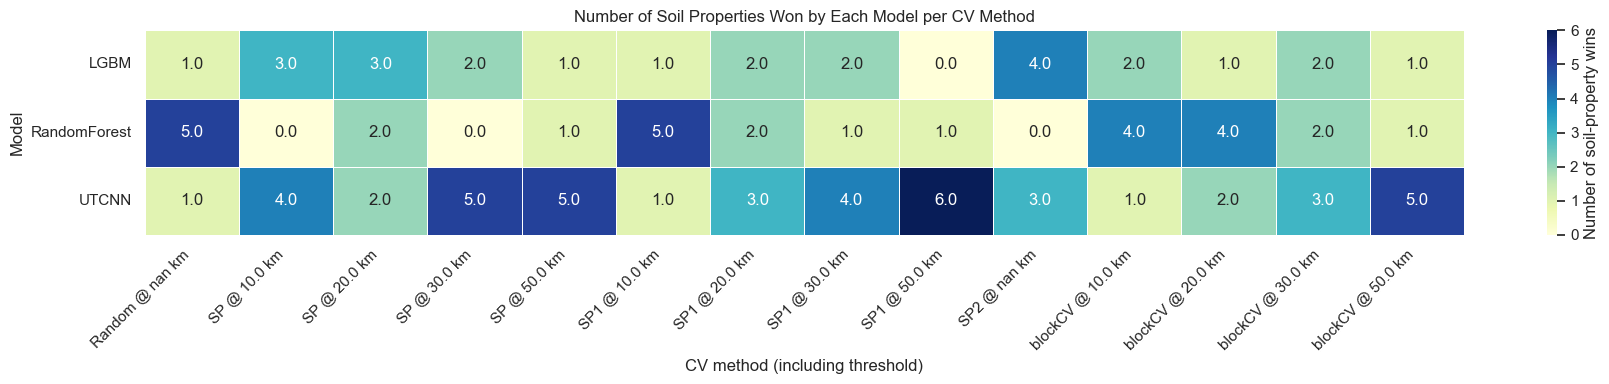

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = df.copy()
# --------------------------------------------------
# 2. Select the best configuration for each model,
#    property and CV method
# --------------------------------------------------
# If multiple configurations exist, keep the row with
# the lowest RMSE for each model/property/CV combination.
# This assumes the configurations are comparable.
data = (
    data.sort_values("rmse")
        .drop_duplicates(
            subset=["model", "soil_property", "cv_method_threshold_km"],
            keep="first"
        )
)

# --------------------------------------------------
# 3. Find the winning model for each property and CV
# --------------------------------------------------
wins = []

for (cv, prop), group in data.groupby(["cv_method_threshold_km", "soil_property"]):
    best_rmse = group["rmse"].min()

    # Models tied for the lowest RMSE
    winners = group[
        np.isclose(group["rmse"], best_rmse, rtol=1e-9, atol=1e-12)
    ]["model"].unique()

    # Fractional credit for ties
    credit = 1 / len(winners)

    for model in winners:
        wins.append({
            "cv_label": cv,
            "soil_property": prop,
            "model": model,
            "win_credit": credit
        })

wins_df = pd.DataFrame(wins)

# --------------------------------------------------
# 4. Count property wins for each model and CV method
# --------------------------------------------------
heatmap_data = wins_df.pivot_table(
    index="model",
    columns="cv_label",
    values="win_credit",
    aggfunc="sum",
    fill_value=0
)

# Optional: arrange columns and rows consistently
heatmap_data = heatmap_data.sort_index(axis=0).sort_index(axis=1)

# --------------------------------------------------
# 5. Plot heatmap
# --------------------------------------------------
plt.figure(figsize=(
    max(10, heatmap_data.shape[1] * 1.3),
    max(4, heatmap_data.shape[0] * 0.8)
))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    cbar_kws={"label": "Number of soil-property wins"}
)

plt.title("Number of Soil Properties Won by Each Model per CV Method")
plt.xlabel("CV method (including threshold)")
plt.ylabel("Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/heatmap_property_wins_by_model_cv.png", dpi=300, bbox_inches="tight")
plt.show()

# Save the values too
heatmap_data.to_csv(f"{OUTPUT_DIR}/heatmap_property_wins_by_model_cv.csv")


In [11]:
df.columns

Index(['soil_property', 'cv_method', 'normalization', 'depth', 'ccp_alpha',
       'criterion', 'max_depth', 'min_samples_split', 'min_samples_leaf',
       'max_features', 'splitter', 'max_leaf_nodes', 'min_impurity_decrease',
       'rmse', 'mse', 'r2', 'mae', 'time', 'model', 'k', 'threshold_m',
       'threshold_km', 'filename', 'nrmse', 'n_estimators', 'min_split_gain',
       'learning_rate', 'min_child_samples', 'colsample_bytree', 'reg_alpha',
       'soil_properties', 'loss', 'optimizer', 'nb_neurones_by_layer', 'lr',
       'dropout_rate', 'hidden_activation', 'output_activation', 'batch_size',
       'epochs', 'history', 'metrics', 'bootstrap', 'random_state',
       'property_label', 'cv_method_threshold_km'],
      dtype='object')

## Average by SP threshold 

Saved summary CSV: cv_visualizations\all\Model_comparison\cv_threshold_comparison\model_comparison_averaged_thresholds.csv
           model soil_property cv_method       rmse        r2  n_thresholds  \
0   DecisionTree            A%        SP  18.902177 -1.038787             0   
1           LGBM            A%        SP  14.049532 -0.117982             0   
2            MLP            A%        SP  18.051442 -0.829123             0   
3   RandomForest            A%        SP  15.769272 -0.405658             0   
4          UTCNN            A%        SP  14.636814 -0.199482             0   
5   DecisionTree            A%       SP1  16.672169 -0.677740             0   
6           LGBM            A%       SP1   9.922645  0.428753             0   
7            MLP            A%       SP1  14.027455 -0.124506             0   
8   RandomForest            A%       SP1  11.213022  0.239339             0   
9          UTCNN            A%       SP1  10.349339  0.388455             0   
10  Deci

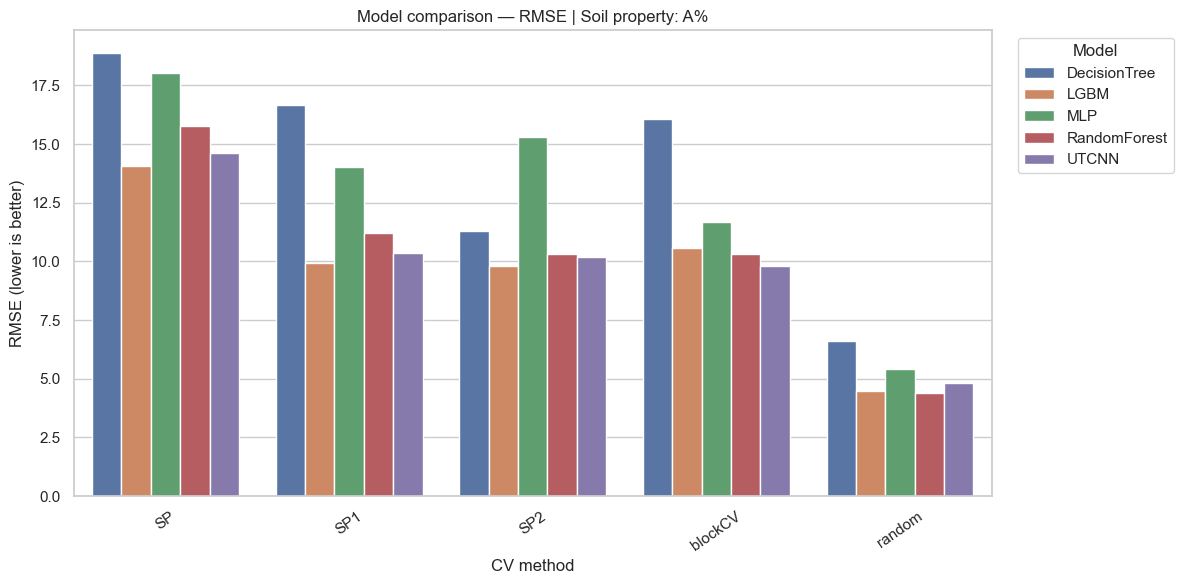

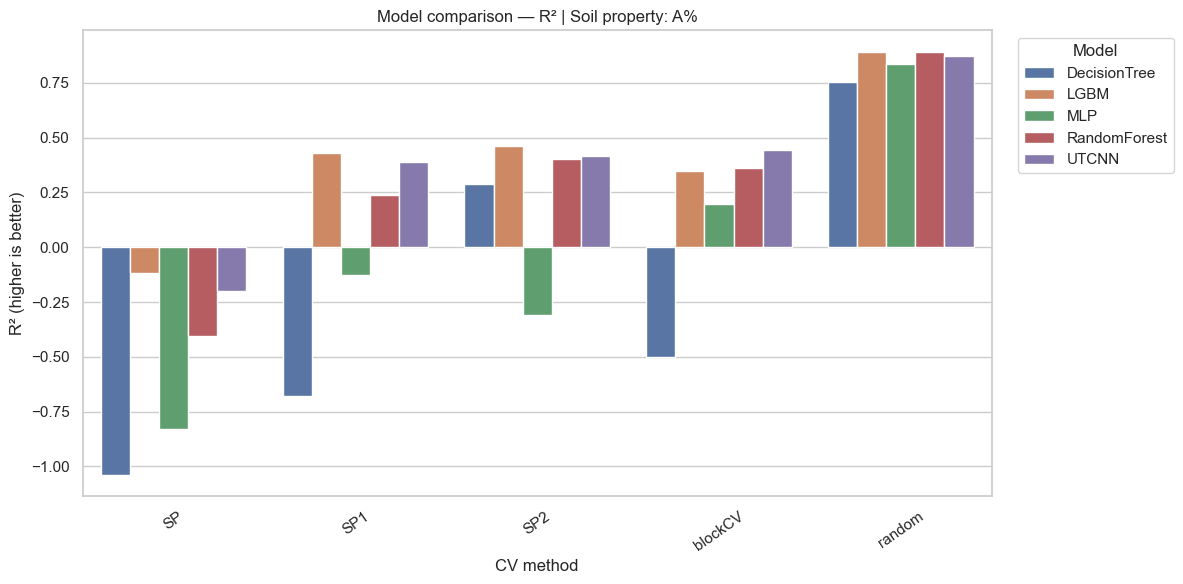

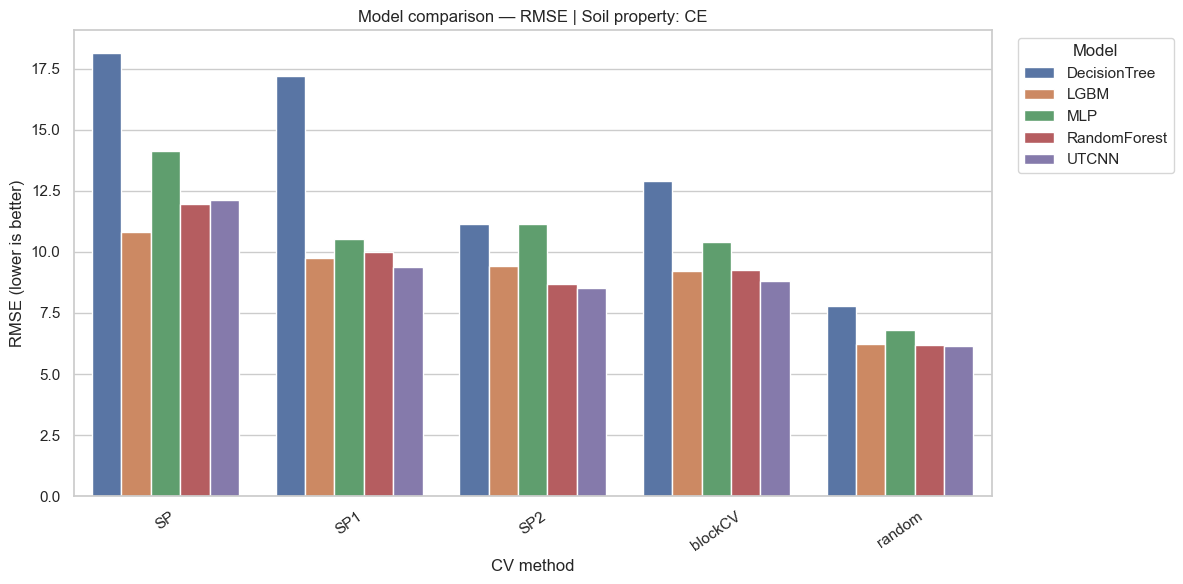

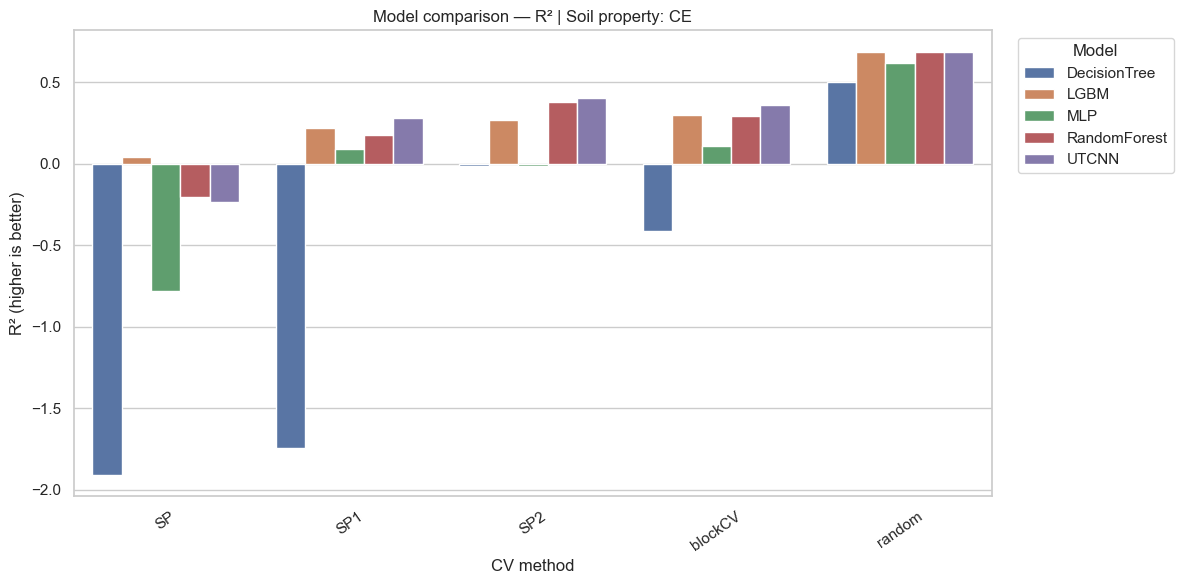

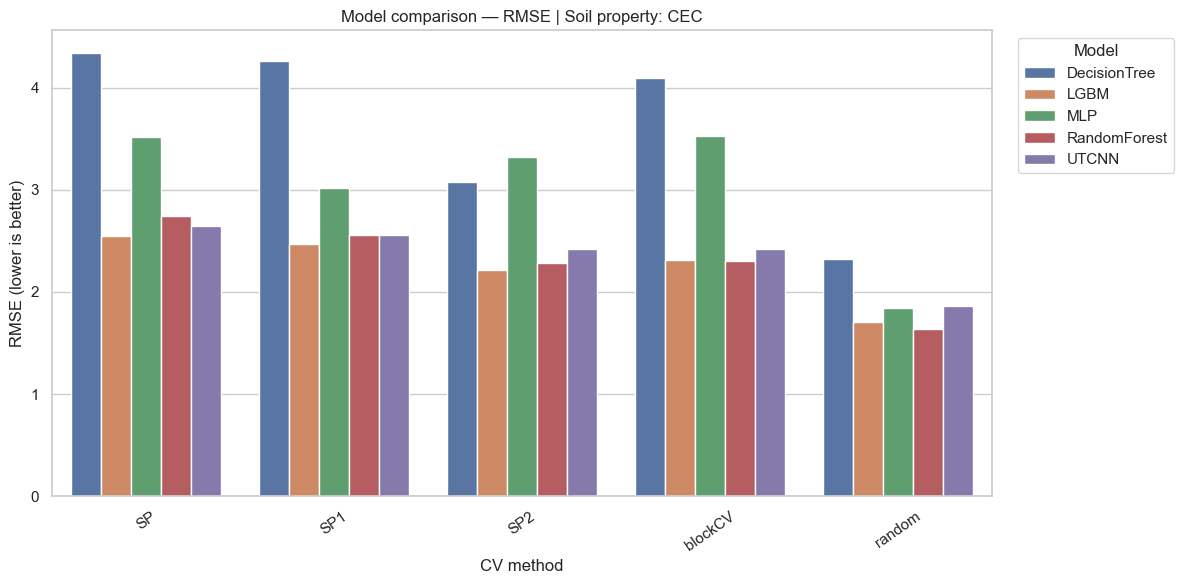

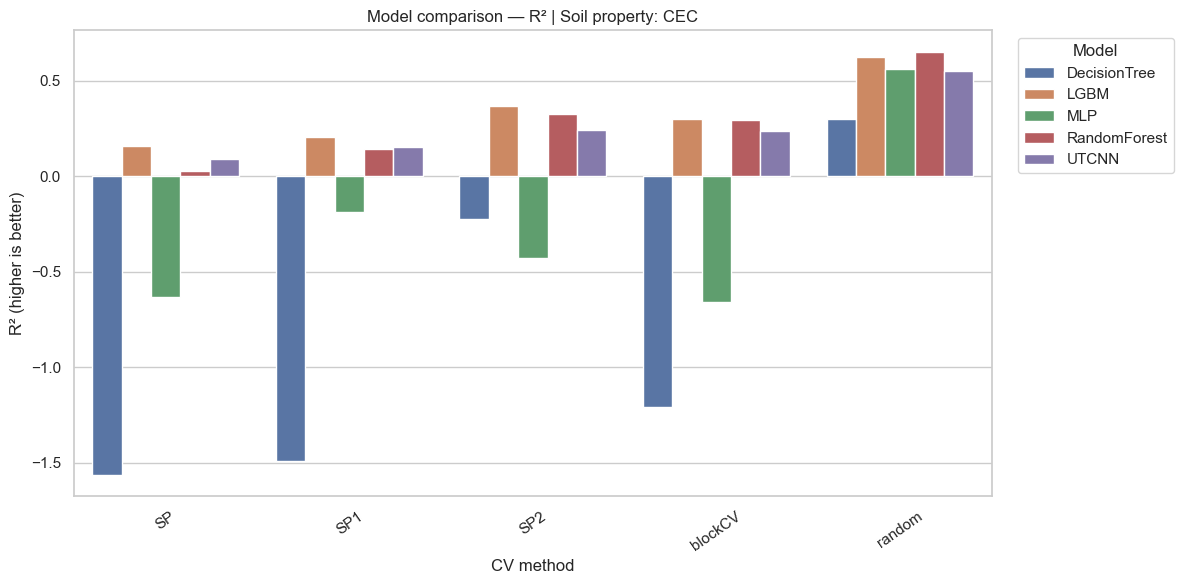

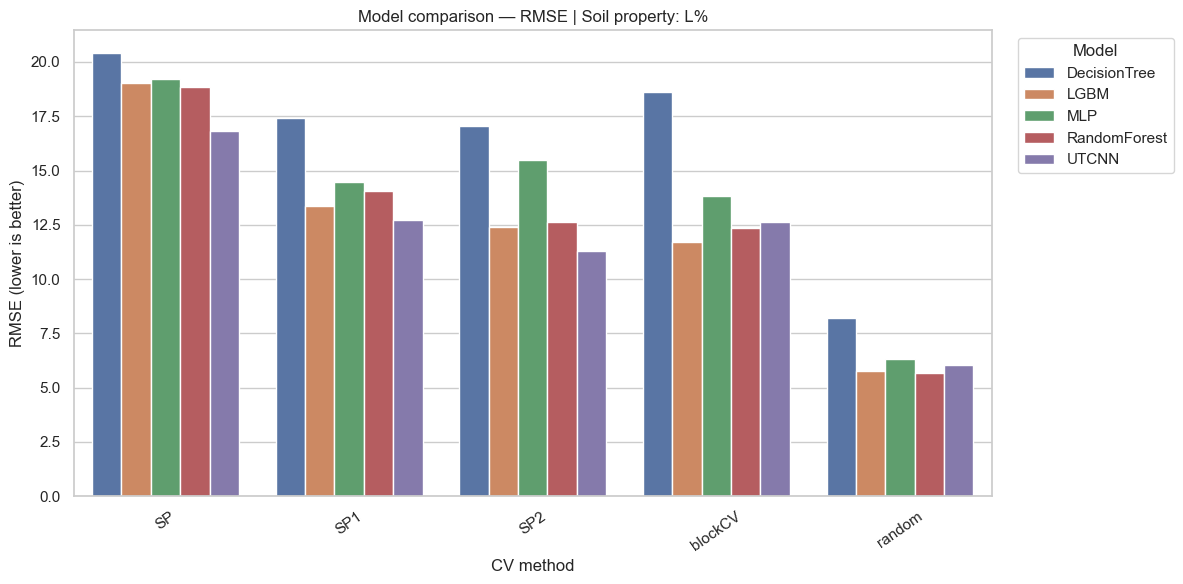

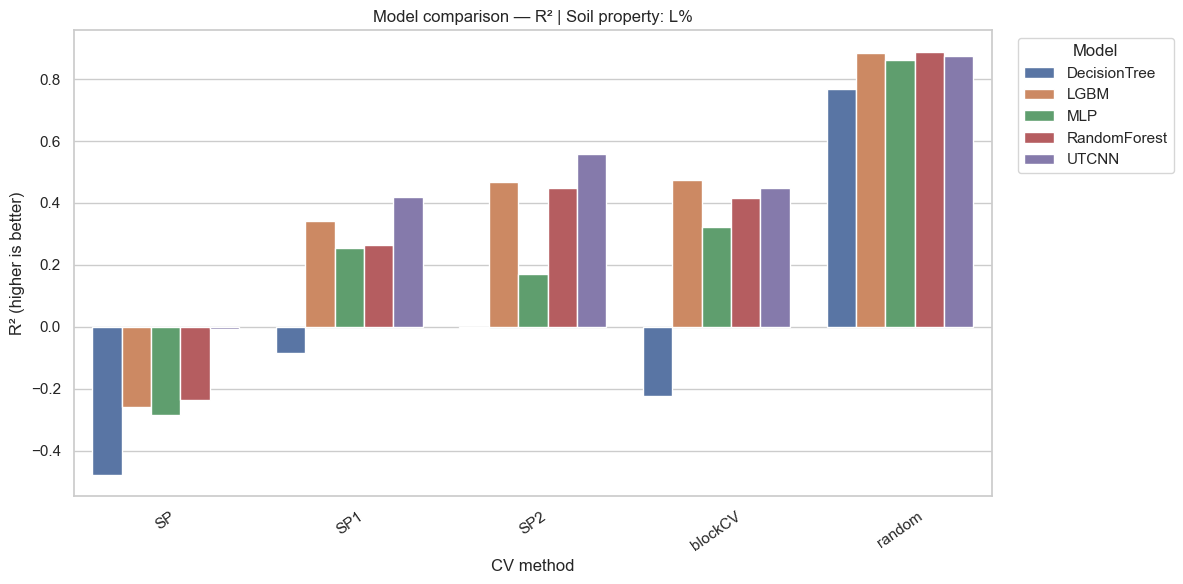

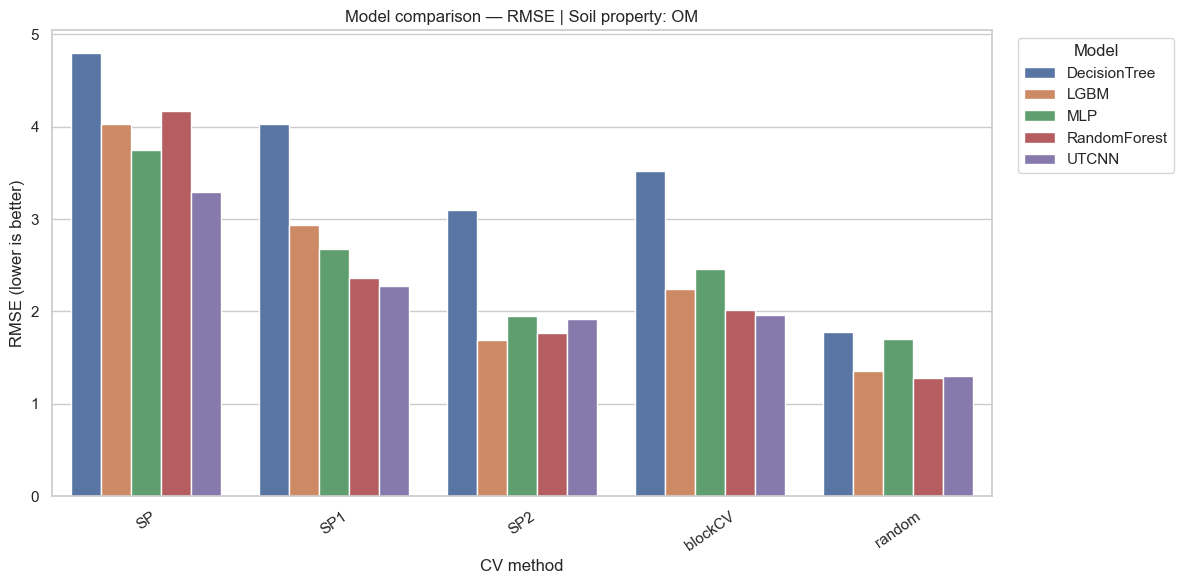

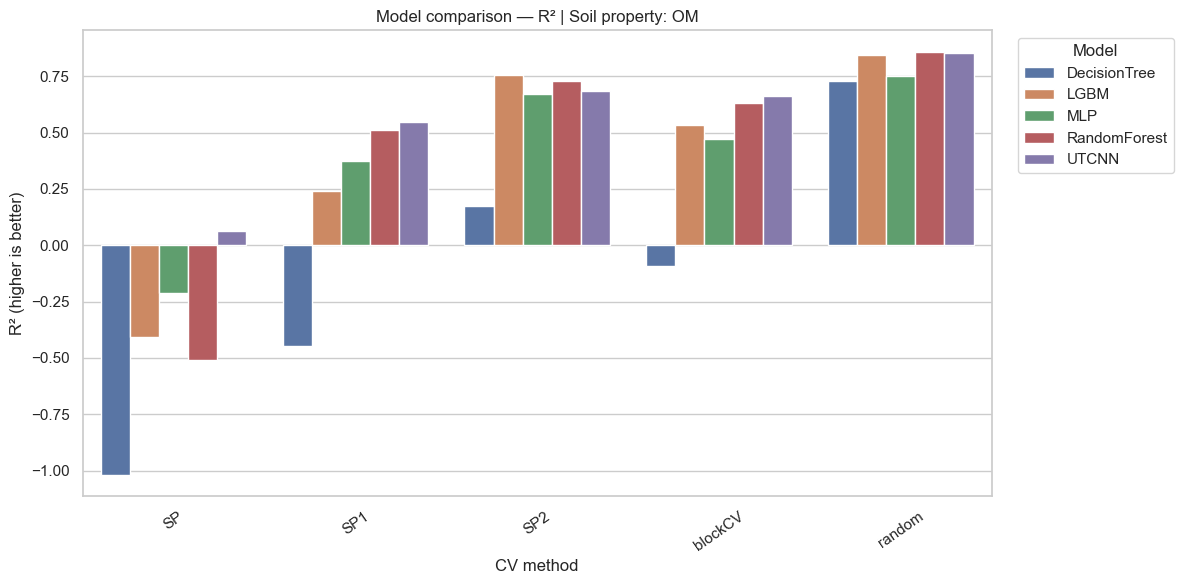

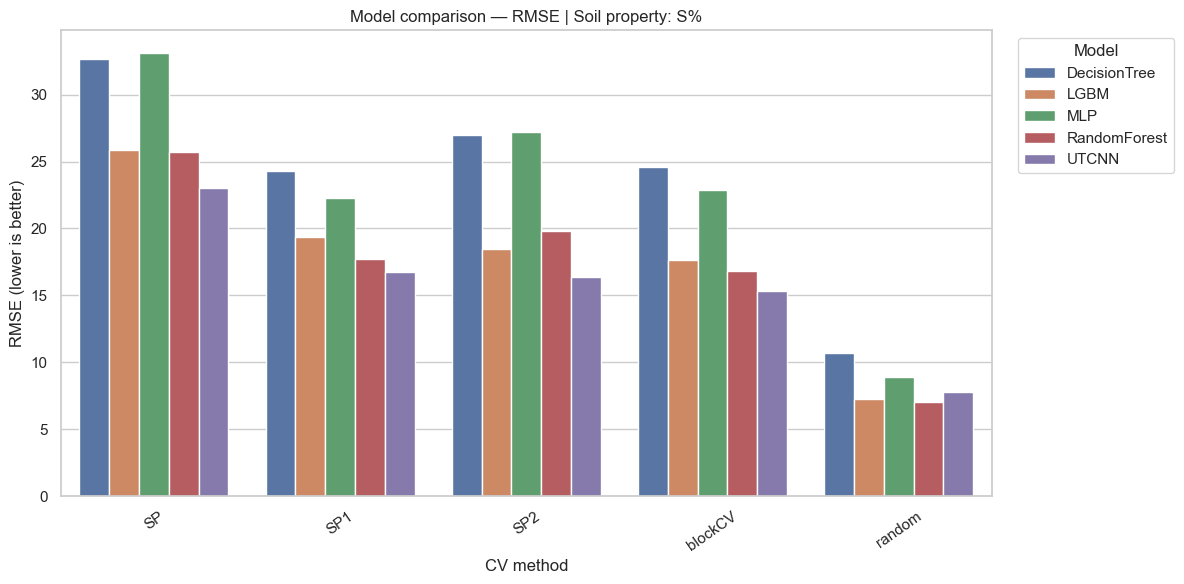

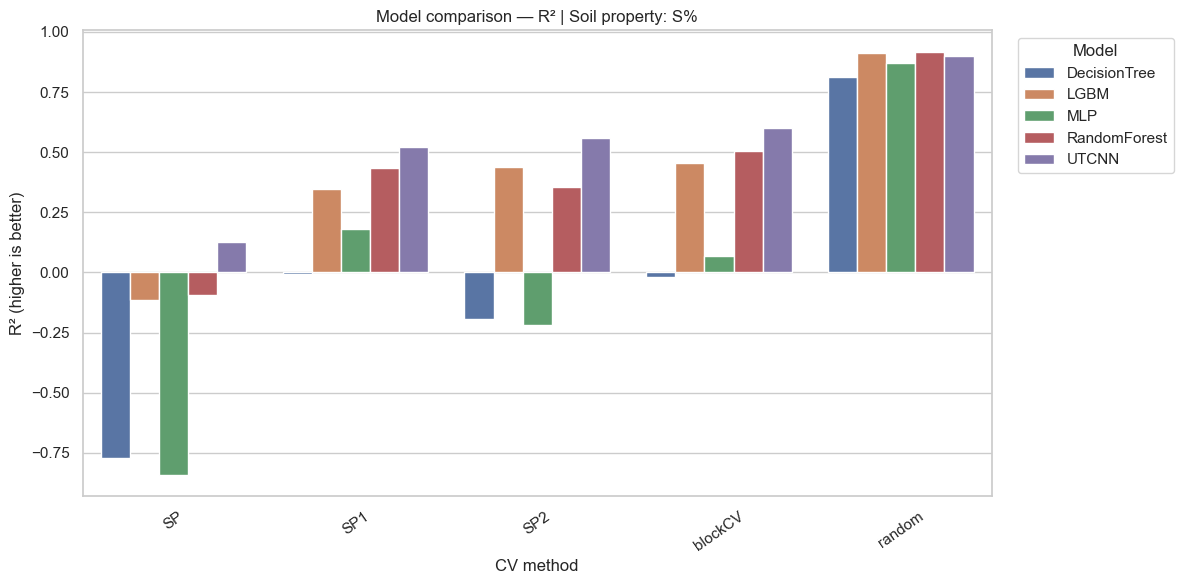

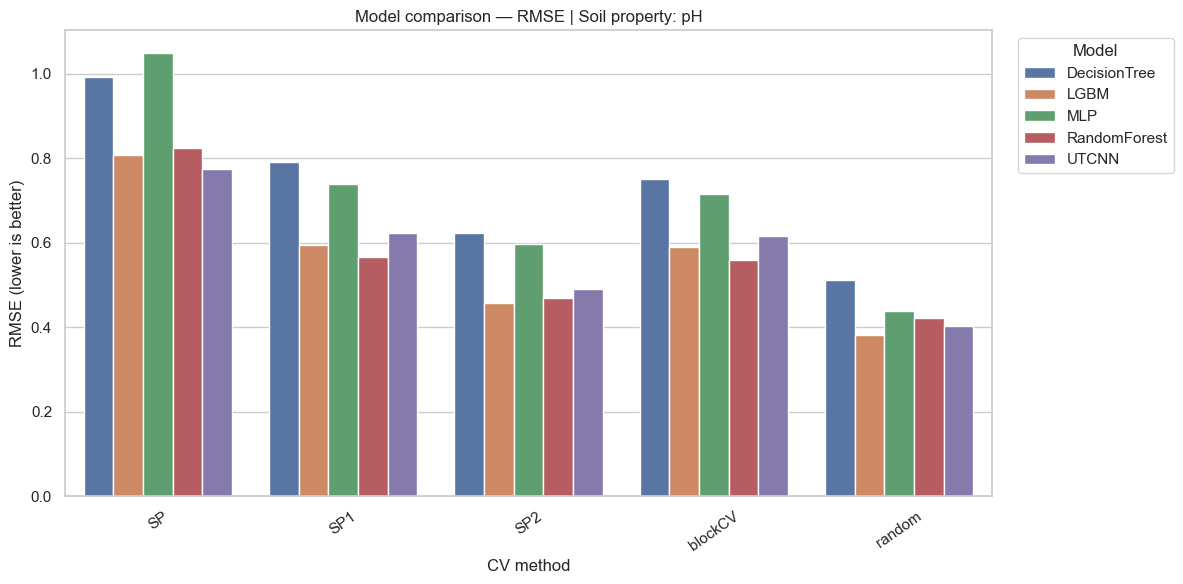

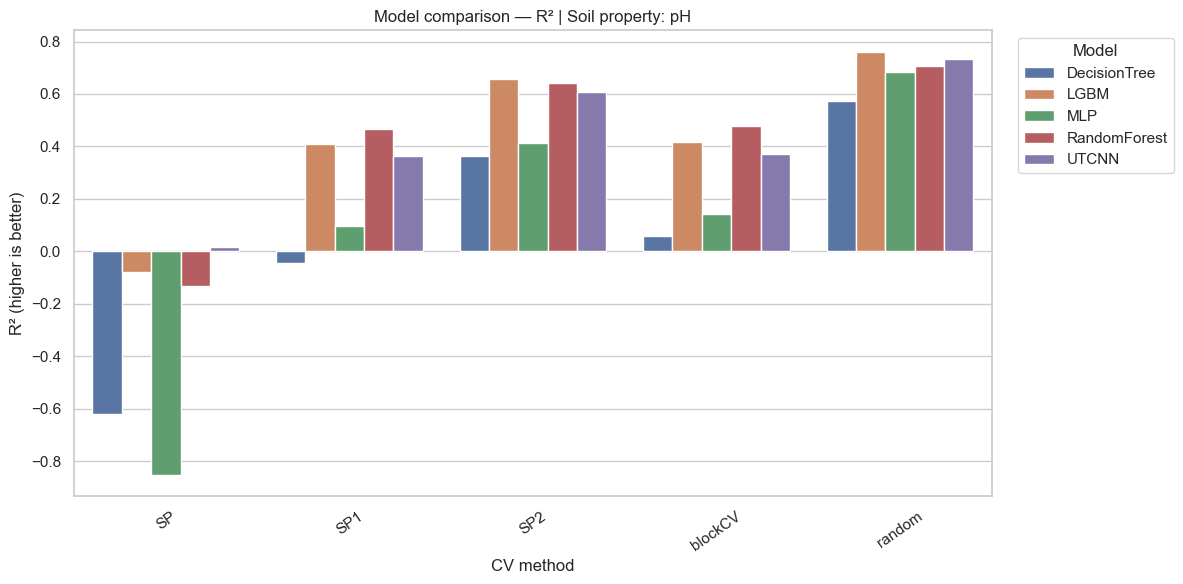

Updated charts saved in: D:\DSM_MODULE\Training\cv_visualizations\all\Model_comparison\cv_threshold_comparison


In [12]:

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================================
# CONFIGURATION
# ==========================================================
region = 'all'
OUTPUT_DIR = Path(f"cv_visualizations/{region}/Model_comparison/cv_threshold_comparison/")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD_METHODS = {"blockcv", "sp1", "sp"}

# Set to "all_depths" if you want to compare that depth only.
# Set to None if the CSV already contains one row per desired
# model/property/CV result, or if you want to summarize all rows.
DEPTH_TO_ANALYZE = "all_depths"


# ==========================================================
# 1. PREPARE DATA
# ==========================================================
data = df.copy()
data.columns = data.columns.str.strip().str.lower()

# Support common alternative column names
rename_map = {
    "soil_properties": "soil_property",
    "property": "soil_property",
    "r_squared": "r2",
    "r²": "r2",
    "cv": "cv_method",
}
data = data.rename(columns={
    old: new for old, new in rename_map.items()
    if old in data.columns and new not in data.columns
})

required = {"model", "soil_property", "cv_method", "rmse", "r2"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in ["model", "soil_property", "cv_method"]:
    data[col] = data[col].astype("string").str.strip()

if DEPTH_TO_ANALYZE is not None and "depth" in data.columns:
    data["depth"] = data["depth"].astype("string").str.strip().str.lower()
    data["depth"] = data["depth"].replace({
        "all_depth": "all_depths"
    })
    data = data[data["depth"] == DEPTH_TO_ANALYZE.lower()].copy()

data["rmse"] = pd.to_numeric(data["rmse"], errors="coerce")
data["r2"] = pd.to_numeric(data["r2"], errors="coerce")

data = data.dropna(
    subset=["model", "soil_property", "cv_method", "rmse", "r2"]
)


# ==========================================================
# 2. STANDARDIZE CV METHOD AND EXTRACT THRESHOLD
# ==========================================================
def parse_cv_method(row):
    """Return (standardized method, threshold)."""

    raw_method = str(row["cv_method"]).strip()

    # If threshold is stored in a separate column, use it.
    if "threshold" in data.columns:
        threshold_value = row.get("threshold", pd.NA)

        if pd.notna(threshold_value) and str(threshold_value).strip().lower() not in {
            "", "none", "nan", "null"
        }:
            threshold = str(threshold_value).strip()
        else:
            threshold = None

        method_text = raw_method
    else:
        # Otherwise, parse labels such as:
        # blockCV_50000, block_100000, SP1_50000, SP_100000
        match = re.match(
            r"^\s*(block[\s_-]*cv|block|sp1|sp2|sp|random)"
            r"(?:[\s_-]+(.+?))?\s*$",
            raw_method,
            flags=re.IGNORECASE,
        )

        if match:
            method_text = match.group(1)
            threshold = match.group(2)
        else:
            method_text = raw_method
            threshold = None

    method_key = re.sub(r"[\s_-]+", "", method_text).lower()

    method_names = {
        "block": "blockCV",
        "blockcv": "blockCV",
        "sp1": "SP1",
        "sp2": "SP2",
        "sp": "SP",
        "random": "random",
    }

    method = method_names.get(method_key, method_text)

    # Threshold is only relevant for these methods.
    if method.lower() not in THRESHOLD_METHODS:
        threshold = None

    return method, threshold


parsed = data.apply(parse_cv_method, axis=1, result_type="expand")
parsed.columns = ["cv_base", "threshold_parsed"]

data["cv_base"] = parsed["cv_base"]
data["threshold_parsed"] = parsed["threshold_parsed"]

# Use a numeric threshold for averaging/grouping where possible.
data["threshold_key"] = data["threshold_parsed"].astype("string").str.strip()


# ==========================================================
# 3. AVERAGE BLOCKCV, SP1 AND SP OVER THEIR THRESHOLDS
# ==========================================================
group_cols = ["model", "soil_property", "cv_base"]

threshold_rows = data[
    data["cv_base"].str.lower().isin(THRESHOLD_METHODS)
].copy()

non_threshold_rows = data[
    ~data["cv_base"].str.lower().isin(THRESHOLD_METHODS)
].copy()

# One result per model/property/method, averaged across thresholds.
threshold_summary = (
    threshold_rows
    .groupby(group_cols, dropna=False)
    .agg(
        rmse=("rmse", "mean"),
        r2=("r2", "mean"),
        n_thresholds=("threshold_key", "nunique"),
        thresholds=("threshold_key",
                    lambda x: ", ".join(sorted(set(x.dropna().astype(str))))),
        n_results=("rmse", "count"),
    )
    .reset_index()
)

# Keep Random and SP2 metrics; if duplicate runs exist, average those
# repeated results within the same model/property/method.
other_summary = (
    non_threshold_rows
    .groupby(group_cols, dropna=False)
    .agg(
        rmse=("rmse", "mean"),
        r2=("r2", "mean"),
        n_thresholds=("threshold_key", "nunique"),
        thresholds=("threshold_key",
                    lambda x: ", ".join(sorted(set(x.dropna().astype(str))))),
        n_results=("rmse", "count"),
    )
    .reset_index()
)

summary = pd.concat(
    [threshold_summary, other_summary],
    ignore_index=True
)

summary = summary.rename(columns={"cv_base": "cv_method"})
summary = summary.sort_values(
    ["soil_property", "cv_method", "model"]
).reset_index(drop=True)

# Save the summarized DataFrame
csv_path = OUTPUT_DIR / "model_comparison_averaged_thresholds.csv"
summary.to_csv(csv_path, index=False)

print(f"Saved summary CSV: {csv_path}")
print(summary.head(20))


# ==========================================================
# 4. PLOT RMSE AND R2, BY PROPERTY
#    X-axis = CV method | Legend = Model
# ==========================================================
import re
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

for prop in sorted(summary["soil_property"].dropna().unique()):
    plot_data = summary[summary["soil_property"] == prop].copy()

    safe_prop = re.sub(r"[^A-Za-z0-9_-]+", "_", str(prop))

    for metric, ylabel, title in [
        ("rmse", "RMSE (lower is better)", "Model comparison — RMSE"),
        ("r2", "R² (higher is better)", "Model comparison — R²"),
    ]:
        fig, ax = plt.subplots(figsize=(12, 6))

        sns.barplot(
            data=plot_data,
            x="cv_method",      # CV methods on the x-axis
            y=metric,
            hue="model",        # Models in the legend
            errorbar=None,
            ax=ax,
        )

        ax.set_title(f"{title} | Soil property: {prop}")
        ax.set_xlabel("CV method")
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)

        ax.legend(
            title="Model",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
        )

        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / f"{metric}_comparison_{safe_prop}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

print(f"Updated charts saved in: {OUTPUT_DIR.resolve()}")



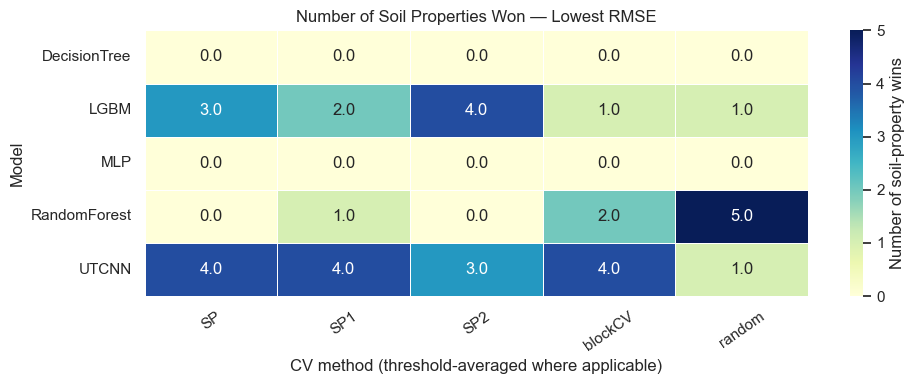

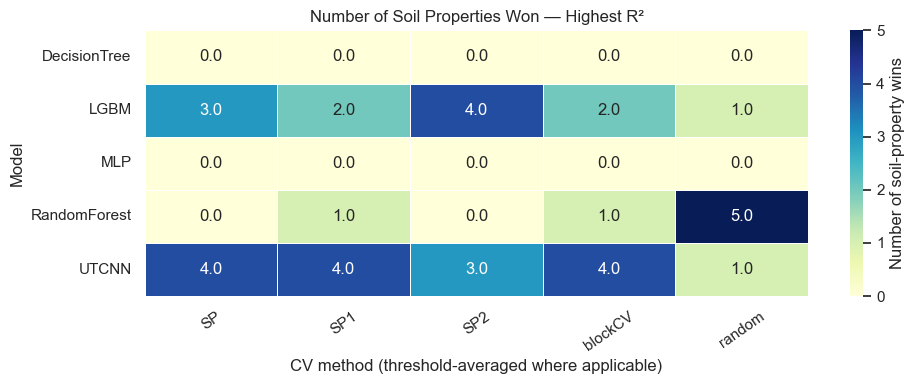

Win heatmaps and their CSV tables have been saved.


In [13]:

# ==========================================================
# 5. WIN HEATMAPS: NUMBER OF SOIL PROPERTIES WON
#    Rows = Models | Columns = CV methods
# ==========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def calculate_property_wins(summary, metric, direction):
    """
    Count how many soil properties each model wins for each CV method.

    direction:
        'min' -> lowest RMSE wins
        'max' -> highest R2 wins

    Ties receive fractional credit.
    """
    wins = []

    for (cv_method, prop), group in summary.groupby(
        ["cv_method", "soil_property"]
    ):
        valid = group.dropna(subset=[metric])

        if valid.empty:
            continue

        best_value = (
            valid[metric].min()
            if direction == "min"
            else valid[metric].max()
        )

        # Account for floating-point precision when detecting ties
        winners = valid[
            np.isclose(
                valid[metric],
                best_value,
                rtol=1e-9,
                atol=1e-12,
            )
        ]["model"].unique()

        credit = 1.0 / len(winners)

        for model in winners:
            wins.append({
                "model": model,
                "cv_method": cv_method,
                "soil_property": prop,
                "win_credit": credit,
            })

    wins_df = pd.DataFrame(wins)

    if wins_df.empty:
        return pd.DataFrame()

    heatmap_data = wins_df.pivot_table(
        index="model",
        columns="cv_method",
        values="win_credit",
        aggfunc="sum",
        fill_value=0,
    )

    # Include all models and CV methods in the summary, even if they win zero times
    all_models = sorted(summary["model"].dropna().unique())
    all_cv_methods = sorted(summary["cv_method"].dropna().unique())

    heatmap_data = heatmap_data.reindex(
        index=all_models,
        columns=all_cv_methods,
        fill_value=0,
    )

    return heatmap_data


# Calculate wins for both metrics
rmse_wins = calculate_property_wins(
    summary,
    metric="rmse",
    direction="min",
)

r2_wins = calculate_property_wins(
    summary,
    metric="r2",
    direction="max",
)


# Plot and save heatmaps
for heatmap_data, metric, title in [
    (
        rmse_wins,
        "rmse",
        "Number of Soil Properties Won — Lowest RMSE",
    ),
    (
        r2_wins,
        "r2",
        "Number of Soil Properties Won — Highest R²",
    ),
]:
    if heatmap_data.empty:
        print(f"No valid wins available for {metric}.")
        continue

    fig, ax = plt.subplots(
        figsize=(
            max(10, heatmap_data.shape[1] * 1.4),
            max(4, heatmap_data.shape[0] * 0.8),
        )
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        vmin=0,
        cbar_kws={"label": "Number of soil-property wins"},
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("CV method (threshold-averaged where applicable)")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"win_heatmap_{metric}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # Save the numeric heatmap data as CSV
    heatmap_data.to_csv(
        OUTPUT_DIR / f"win_heatmap_{metric}.csv"
    )

print("Win heatmaps and their CSV tables have been saved.")


## Threshold Effect 

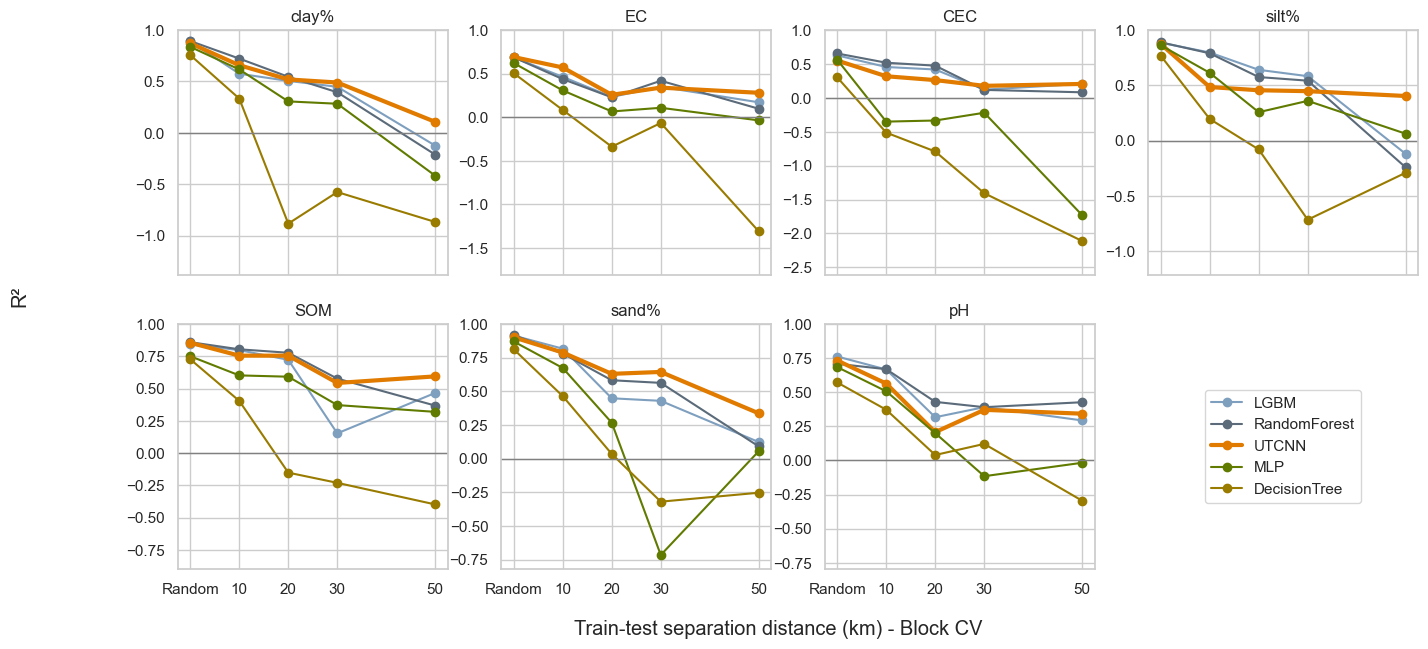

In [14]:
import matplotlib.pyplot as plt

props = ["A%", "CE", "CEC", "L%", "OM", "S%", "pH"]
title_property_map = {prop: prop for prop in props}  # Customize if needed
title_property_map['A%'] = 'clay%'
title_property_map['S%'] = 'sand%'
title_property_map['L%'] = 'silt%'
title_property_map['CE'] = 'EC'
title_property_map['OM'] = 'SOM'

models = {"LGBM": "#7f9fbf", "RandomForest": "#5b6b7a", "UTCNN": "#e07b00", "MLP": "#607b00", "DecisionTree": "#997b00"}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)

for ax, p in zip(axes.flat, props):
    for m, c in models.items():
        s = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "blockCV")].sort_values("threshold_km")
        r = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "Random")].r2.iloc[0]
        x = [0] + s.threshold_km.tolist()   # 60 km for SP2
        y = [r] + s.r2.tolist() 
        lw = 3 if m == "UTCNN" else 1.5
        ax.plot(x, y, "-o", color=c, lw=lw, label=m)
        # ax.fill_between(s.threshold_km, s.r2 - s.r2_sd, s.r2 + s.r2_sd, color=c, alpha=0.15)
    ax.axhline(0, color="grey", lw=1)
    ax.set_ylim(min(y) - 0.5, 1); ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0, 10, 20, 30, 50]); ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.supxlabel("Train-test separation distance (km) - Block CV"); fig.supylabel("R²")
fig.savefig(
        OUTPUT_DIR / f"Threshold-effect-blockCV.png",
        dpi=300,
        bbox_inches="tight",
    )

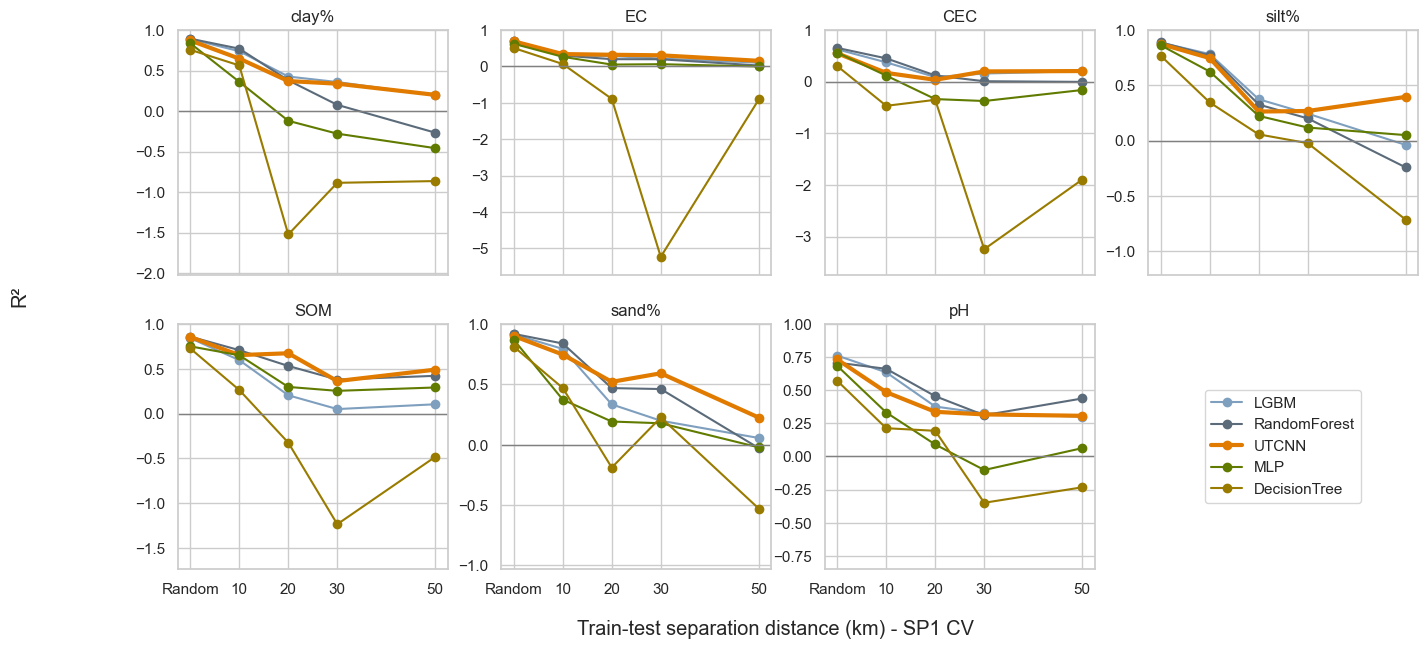

In [15]:
import matplotlib.pyplot as plt

props = ["A%", "CE", "CEC", "L%", "OM", "S%", "pH"]
models = {"LGBM": "#7f9fbf", "RandomForest": "#5b6b7a", "UTCNN": "#e07b00", "MLP": "#607b00", "DecisionTree": "#997b00"}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)

for ax, p in zip(axes.flat, props):
    for m, c in models.items():
        s = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "SP1") ].sort_values("threshold_km")
        r = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "Random")].r2.iloc[0]
        x = [0] + s.threshold_km.tolist()
        y = [r] + s.r2.tolist()
        lw = 3 if m == "UTCNN" else 1.5
        ax.plot(x, y, "-o", color=c, lw=lw, label=m)
        # ax.fill_between(s.threshold_km, s.r2 - s.r2_sd, s.r2 + s.r2_sd, color=c, alpha=0.15)
    ax.axhline(0, color="grey", lw=1)
    ax.set_ylim(min(y) - 0.5, 1); ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0,   10, 20, 30, 50]); ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.supxlabel("Train-test separation distance (km) - SP1 CV "); fig.supylabel("R²")
fig.savefig(
        OUTPUT_DIR / f"Threshold-effect-SP1CV.png",
        dpi=300,
        bbox_inches="tight",
    )

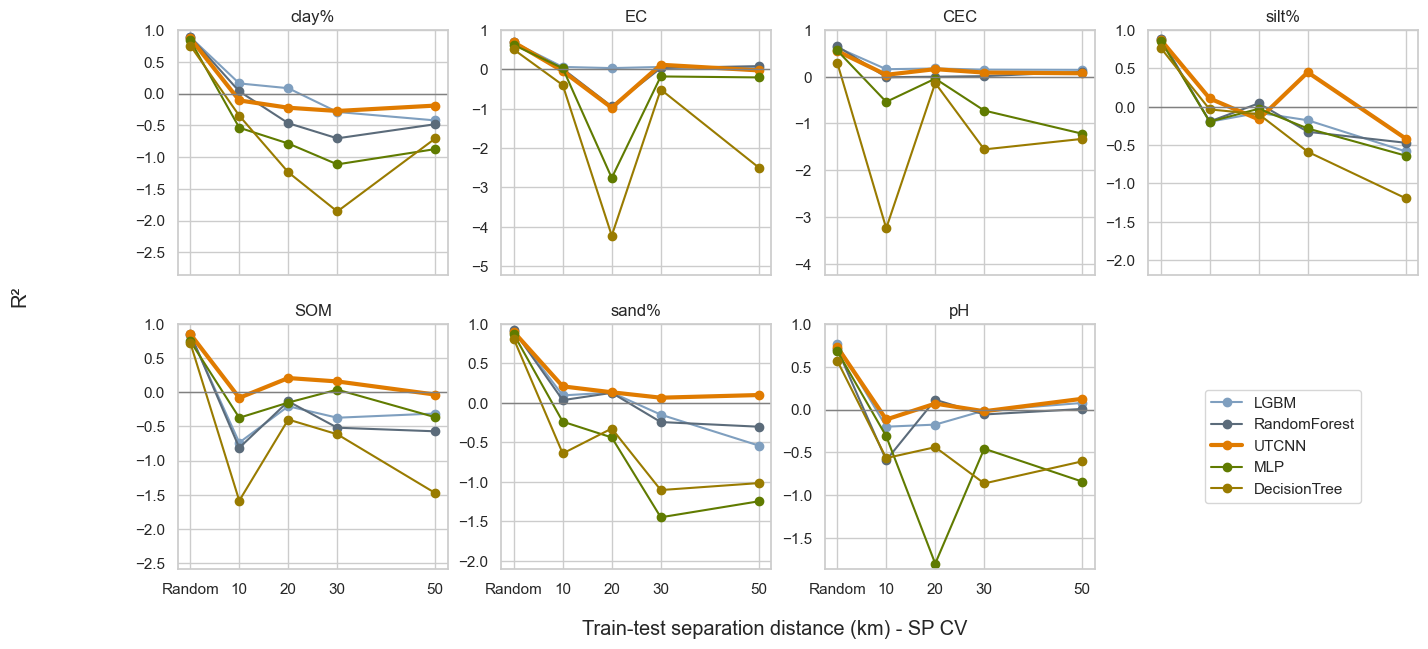

In [16]:
import matplotlib.pyplot as plt

props = ["A%", "CE", "CEC", "L%", "OM", "S%", "pH"]
models = {"LGBM": "#7f9fbf", "RandomForest": "#5b6b7a", "UTCNN": "#e07b00", "MLP": "#607b00", "DecisionTree": "#997b00"}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)

for ax, p in zip(axes.flat, props):
    for m, c in models.items():
        s = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "SP") ].sort_values("threshold_km")
        r = df[(df.property_label == p) & (df.model == m) & (df.cv_method == "Random")].r2.iloc[0]
        x = [0] + s.threshold_km.tolist()
        y = [r] + s.r2.tolist()
        lw = 3 if m == "UTCNN" else 1.5
        ax.plot(x, y, "-o", color=c, lw=lw, label=m)
        # ax.fill_between(s.threshold_km, s.r2 - s.r2_sd, s.r2 + s.r2_sd, color=c, alpha=0.15)
    ax.axhline(0, color="grey", lw=1)
    ax.set_ylim(min(y) - 1, 1); ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0,   10, 20, 30, 50]); ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.supxlabel("Train-test separation distance (km) - SP CV "); fig.supylabel("R²")
fig.savefig(
        OUTPUT_DIR / f"Threshold-effect-SPCV.png",
        dpi=300,
        bbox_inches="tight",
    )

# multitask cnn 

## combine all mtcnn results 

In [17]:

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================================
# CONFIGURATION
# ==========================================================
BASE_DIR = Path(
    r"cv_optuna_mtcnn/test_best_random_on_spCV"
)

OUTPUT_DIR = Path("cv_visualizations/Results_MTCNN_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Average over thresholds for these methods
THRESHOLD_METHODS = {"blockcv", "sp1", "sp"}

# If you only want all-depth results, set this to "all_depths".
# Use None to keep every task/depth.
DEPTH_TO_ANALYZE = None


# ==========================================================
# HELPERS
# ==========================================================
def normalize_method(method_name):
    """
    Examples:
        random         -> ('random', None)
        sp_k5_10000    -> ('sp', 10000)
        sp1_k5_10000   -> ('sp1', 10000)
        sp2_k5         -> ('sp2', None)
        block_k5_10000 -> ('block', 10000)
    """
    name = str(method_name).strip().lower()

    # Random CV
    if name == "random":
        return "random", None

    # Methods with a threshold: sp_k5_10000, sp1_k5_10000, block_k5_10000
    match = re.fullmatch(r"(sp1|sp2|sp|block)_k\d+(?:_(\d+))?", name)

    if match:
        cv_method = match.group(1)
        threshold = int(match.group(2)) if match.group(2) else None
        return cv_method, threshold

    raise ValueError(f"Unrecognized CV method name: {method_name}")
def find_column(df, candidates, required=True):
    """Find a column while ignoring case and common separators."""

    def clean(name):
        return re.sub(r"[^a-z0-9]", "", str(name).lower())

    lookup = {clean(col): col for col in df.columns}

    for candidate in candidates:
        key = clean(candidate)
        if key in lookup:
            return lookup[key]

    if required:
        raise ValueError(
            f"Could not find any of {candidates}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


# ==========================================================
# 1. READ EVERY metrics_by_task.csv
# ==========================================================
files = sorted(BASE_DIR.glob("**/metrics_by_task.csv"))

if not files:
    raise FileNotFoundError(
        f"No metrics_by_task.csv files found under {BASE_DIR.resolve()}"
    )

all_results = []

for file_path in files:
    # Expected location:
    # BASE_DIR / cv_folder / property_folder / metrics_by_task.csv
    cv_folder = file_path.parent.parent.name
    property_folder = file_path.parent.name

    result = pd.read_csv(file_path)
    result.columns = result.columns.str.strip()

    # Identify the task/depth and metric columns
    task_col = find_column(
        result,
        ["task", "depth", "task_name", "depth_interval", "target"]
    )
    rmse_col = find_column(result, ["RMSE"])
    r2_col = find_column(result, ["R2", "R_squared", "R²"])

    mse_col = find_column(
        result, ["MSE", "mean_squared_error"], required=False
    )
    mae_col = find_column(
        result, ["mae", "mean_absolute_error"], required=False
    )

    method, embedded_threshold = normalize_method(cv_folder)

    result = result.rename(columns={
        task_col: "task",
        rmse_col: "rmse",
        r2_col: "r2",
    })

    if mse_col:
        result = result.rename(columns={mse_col: "mse"})

    if mae_col:
        result = result.rename(columns={mae_col: "mae"})

    result["soil_property"] = property_folder.split("output")[1]
    result["cv_method_original"] = cv_folder
    result["cv_method"] = method
    result["threshold"] = embedded_threshold
    result["source_file"] = str(file_path)
    result["model"] = "MTCNN"

    # Use an explicit threshold column if one exists and has values.
    threshold_col = find_column(
        result, ["threshold", "distance_threshold"], required=False
    )

    if threshold_col and threshold_col != "threshold":
        result["threshold"] = result[threshold_col].where(
            result[threshold_col].notna(),
            result["threshold"]
        )

    all_results.append(result)

# Combined raw results
mtcnn_df = pd.concat(all_results, ignore_index=True)

# Standardize task labels and metrics
mtcnn_df["task"] = mtcnn_df["task"].astype(str).str.strip()
mtcnn_df["soil_property"] = (
    mtcnn_df["soil_property"].astype(str).str.strip()
)

for col in ["rmse", "r2", "mse", "mae"]:
    if col in mtcnn_df.columns:
        mtcnn_df[col] = pd.to_numeric(
            mtcnn_df[col], errors="coerce"
        )

if DEPTH_TO_ANALYZE is not None:
    mtcnn_df = mtcnn_df[
        mtcnn_df["task"].str.lower() == DEPTH_TO_ANALYZE.lower()
    ].copy()

raw_path = OUTPUT_DIR / "MTCNN_all_properties_all_cv_methods.csv"
mtcnn_df.to_csv(raw_path, index=False)

print(f"Files loaded: {len(files)}")
print(f"Combined rows: {len(mtcnn_df)}")
print(f"Saved: {raw_path}")
print("\nCV methods:")
print(mtcnn_df[["cv_method_original", "cv_method", "threshold"]]
      .drop_duplicates()
      .sort_values(["cv_method", "cv_method_original"])
      .to_string(index=False))

print("\nAvailable columns:")
print(mtcnn_df.columns.tolist())


Files loaded: 98
Combined rows: 588
Saved: cv_visualizations\Results_MTCNN_comparison\MTCNN_all_properties_all_cv_methods.csv

CV methods:
cv_method_original cv_method threshold
    block_k5_10000     block     10000
    block_k5_20000     block     20000
    block_k5_30000     block     30000
    block_k5_50000     block     50000
            random    random      None
       sp_k5_10000        sp     10000
       sp_k5_20000        sp     20000
       sp_k5_30000        sp     30000
       sp_k5_50000        sp     50000
      sp1_k5_10000       sp1     10000
      sp1_k5_20000       sp1     20000
      sp1_k5_30000       sp1     30000
      sp1_k5_50000       sp1     50000
            sp2_k5       sp2      None

Available columns:
['fold', 'task', 'mse', 'rmse', 'r2', 'soil_property', 'cv_method_original', 'cv_method', 'threshold', 'source_file', 'model']


## threshold averaged CSV 

In [18]:

# ==========================================================
# 2. AVERAGE METRICS ACROSS THRESHOLDS
# ==========================================================

group_cols = ["soil_property", "task", "cv_method"]

# Make sure the threshold is available as a string for reporting
mtcnn_df["threshold"] = (
    mtcnn_df["threshold"].astype("string").str.strip()
)

threshold_rows = mtcnn_df[
    mtcnn_df["cv_method"].str.lower().isin(THRESHOLD_METHODS)
].copy()

other_rows = mtcnn_df[
    ~mtcnn_df["cv_method"].str.lower().isin(THRESHOLD_METHODS)
].copy()

metric_cols = [
    col for col in ["rmse", "r2", "mse", "mae"]
    if col in mtcnn_df.columns
]


def summarize_group(group):
    """Average available metrics and retain threshold information."""

    output = {}

    for metric in metric_cols:
        output[metric] = group[metric].mean()

    thresholds = sorted(
        group["threshold"].dropna().astype(str).unique()
    )

    output["n_thresholds"] = len(thresholds)
    output["thresholds"] = ", ".join(thresholds)
    output["n_results"] = len(group)

    return pd.Series(output)


# Average threshold-based methods
averaged_thresholds = (
    threshold_rows
    .groupby(group_cols, dropna=False)
    .apply(summarize_group)
    .reset_index()
)

# Retain Random and SP2 metrics.
# If multiple runs exist per property/task/method, their metrics
# are averaged to ensure a single summary row.
retained_methods = (
    other_rows
    .groupby(group_cols, dropna=False)
    .apply(summarize_group)
    .reset_index()
)

mtcnn_avg_df = pd.concat(
    [averaged_thresholds, retained_methods],
    ignore_index=True
)

mtcnn_avg_df = mtcnn_avg_df.sort_values(
    ["soil_property", "task", "cv_method"]
).reset_index(drop=True)

avg_path = OUTPUT_DIR / "MTCNN_average_by_property_task_cv_method.csv"
mtcnn_avg_df.to_csv(avg_path, index=False)

print(f"Saved: {avg_path}")
print(mtcnn_avg_df.head(20))


Saved: cv_visualizations\Results_MTCNN_comparison\MTCNN_average_by_property_task_cv_method.csv
   soil_property       task cv_method       rmse        r2         mse  \
0             A%      0-5cm     block  10.749402  0.410267  115.993899   
1             A%      0-5cm    random   6.868781  0.760128   47.180155   
2             A%      0-5cm        sp  15.778842 -0.266098  249.027327   
3             A%      0-5cm       sp1  11.428268  0.327629  132.247812   
4             A%      0-5cm       sp2  12.072025  0.259064  145.733787   
5             A%  100-200cm     block  11.775023  0.356040  144.342619   
6             A%  100-200cm    random   5.062205  0.885674   25.625916   
7             A%  100-200cm        sp  16.953393 -0.284367  287.888800   
8             A%  100-200cm       sp1  13.002135  0.212205  176.582973   
9             A%  100-200cm       sp2  13.023452  0.243312  169.610305   
10            A%    15-30cm     block  11.534111  0.339513  134.011480   
11            A% 

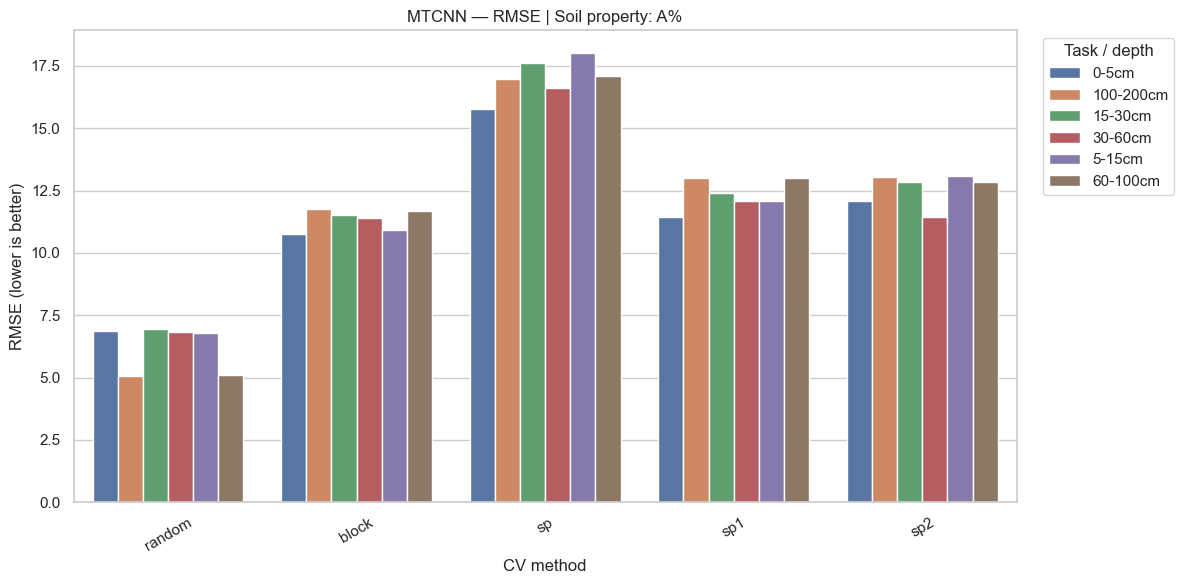

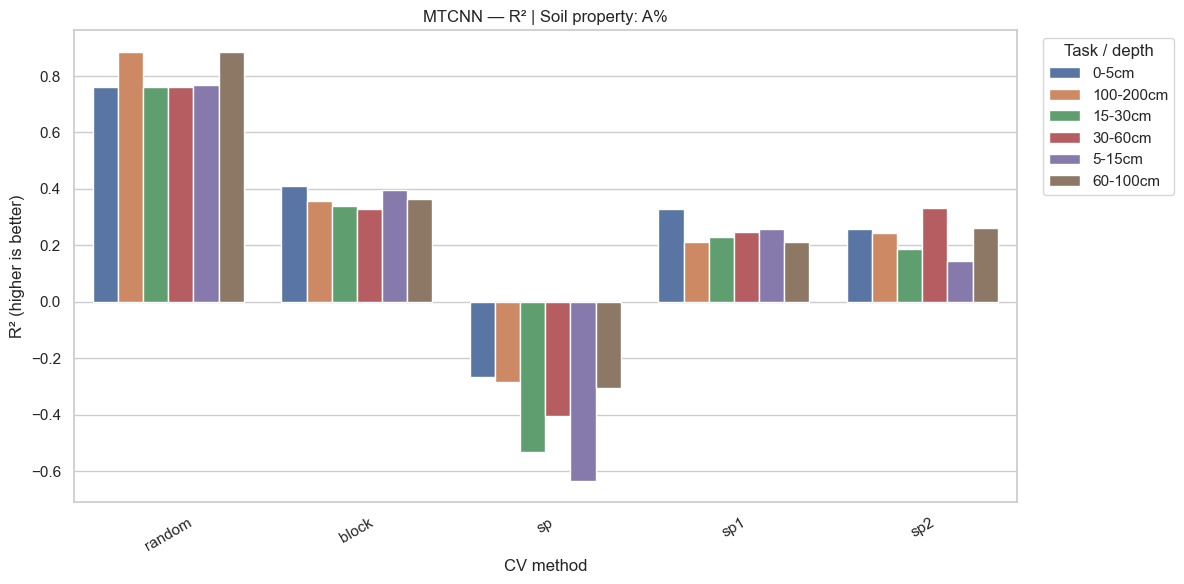

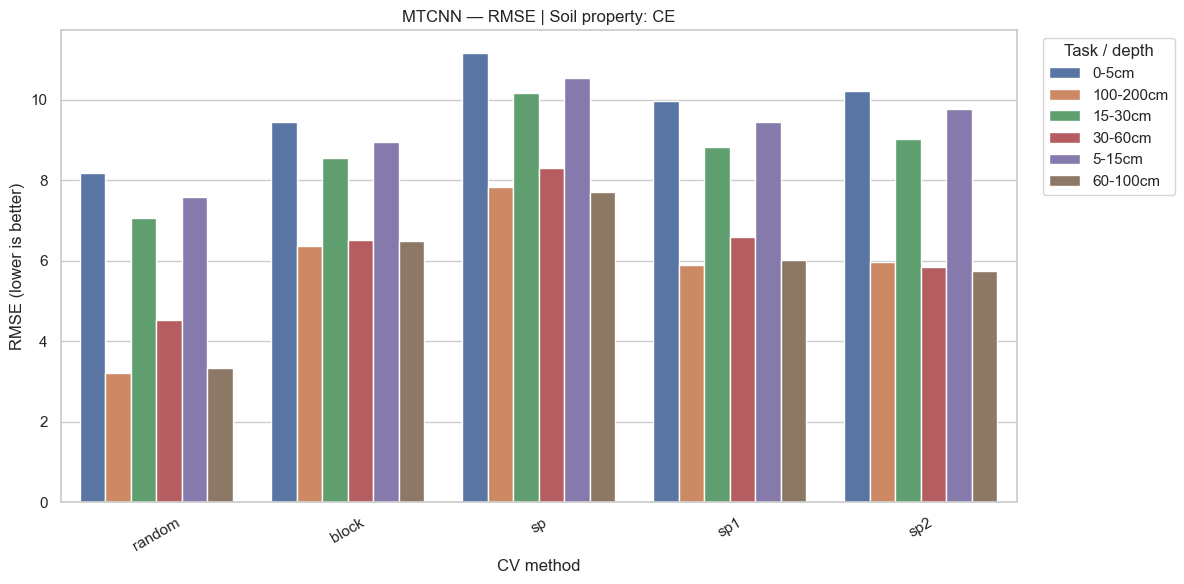

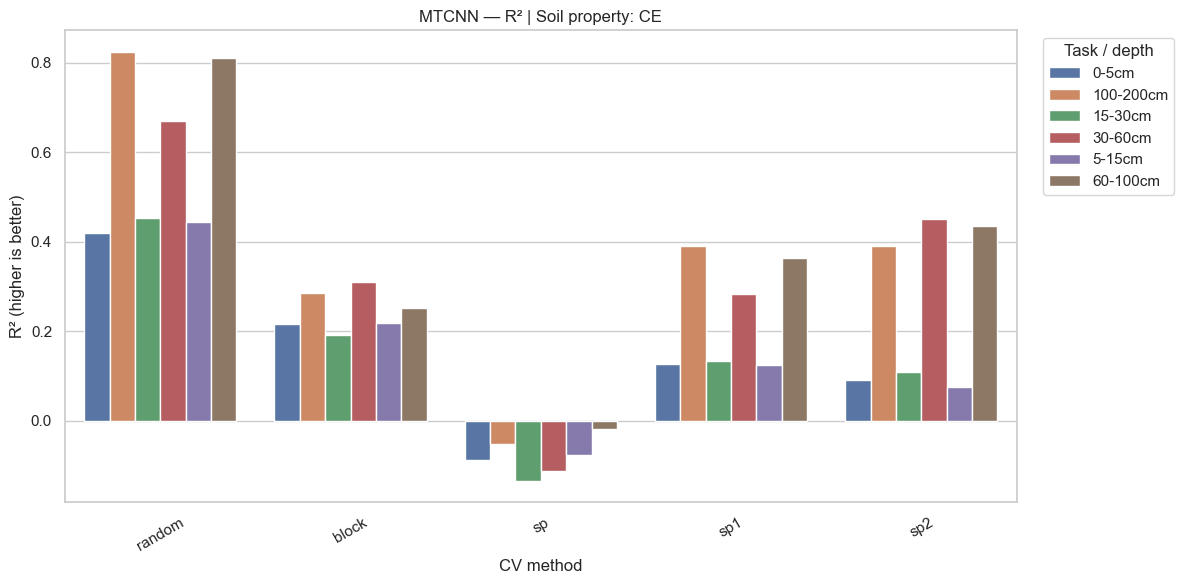

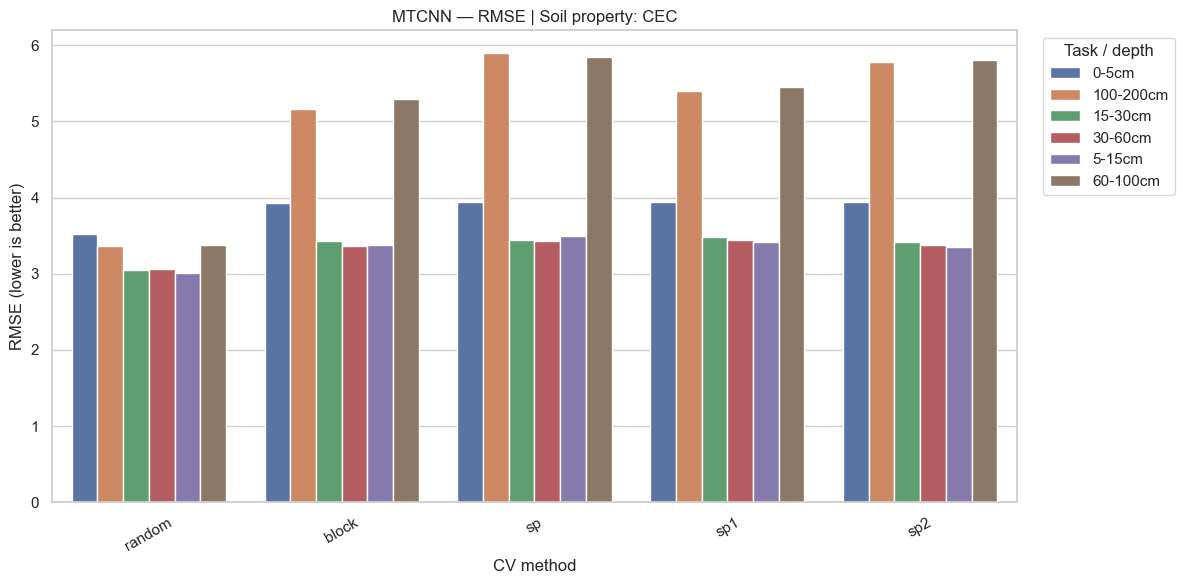

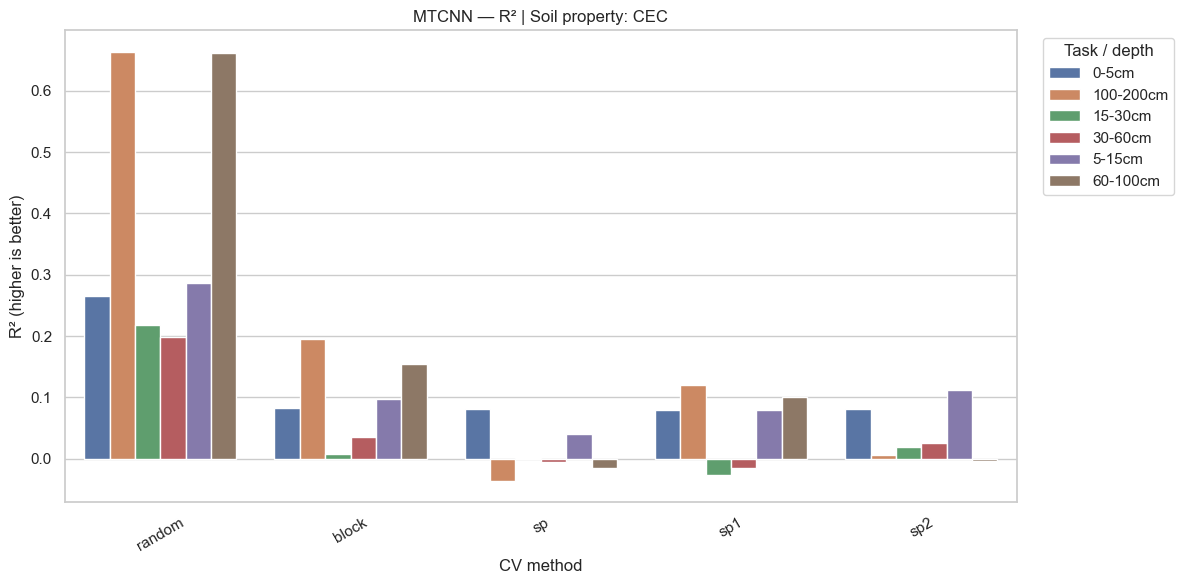

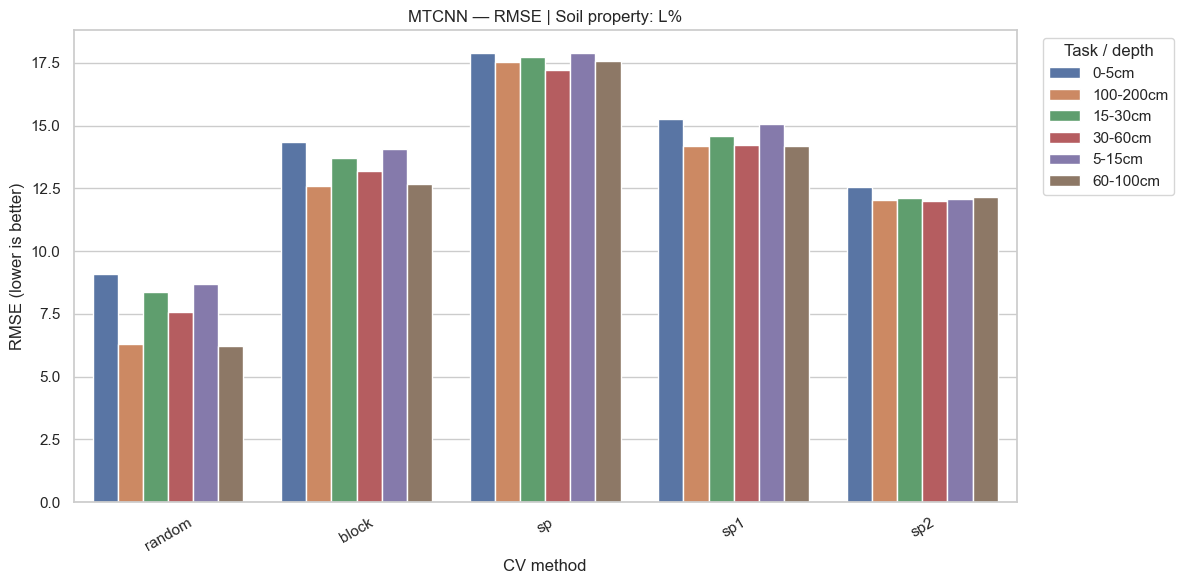

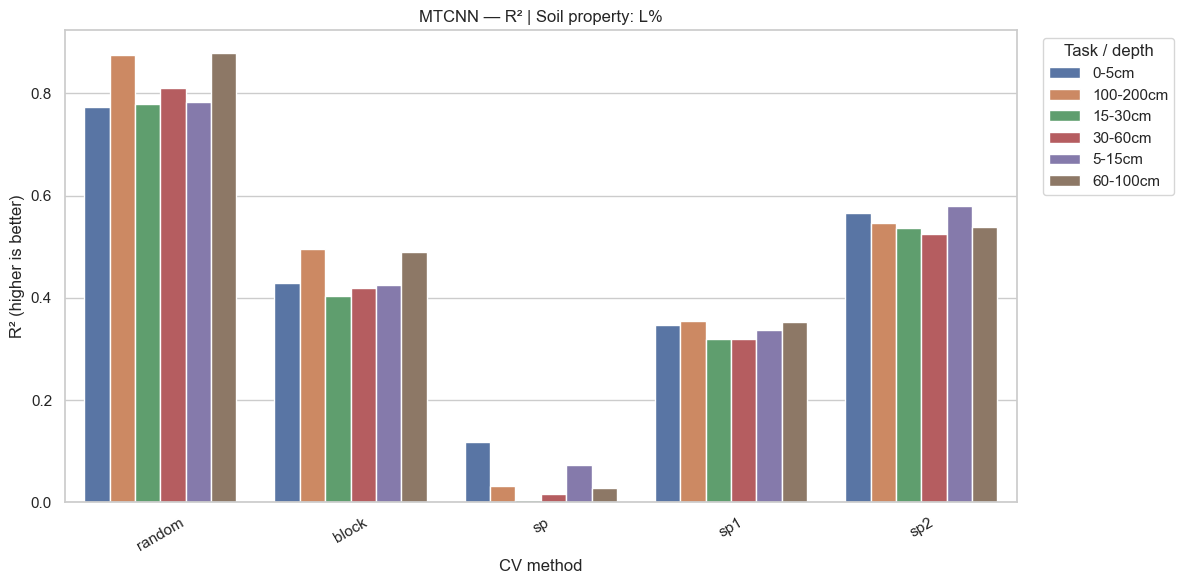

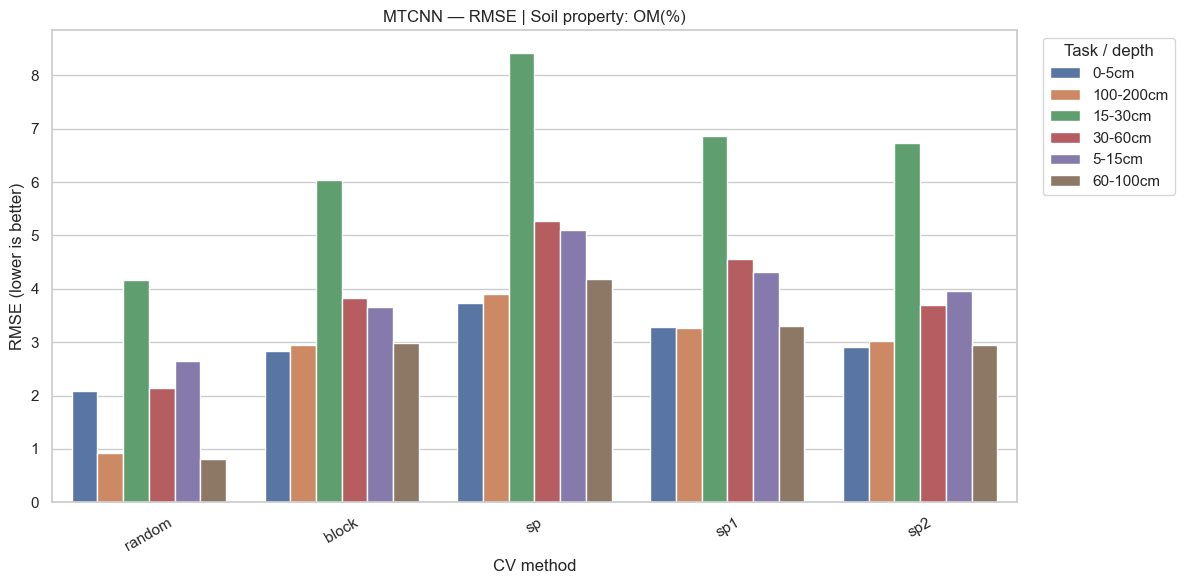

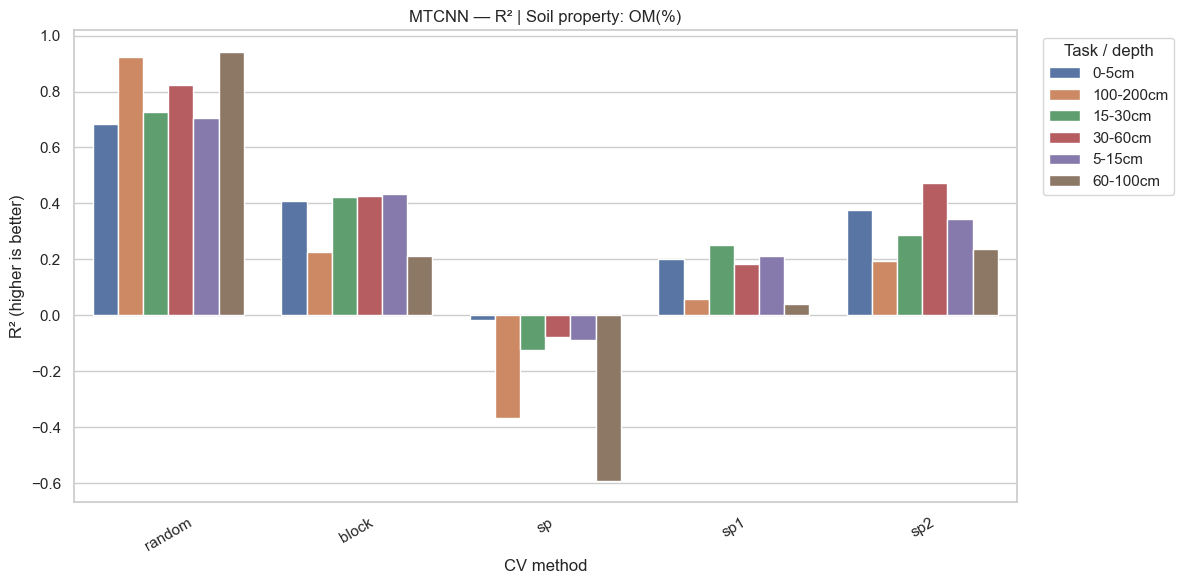

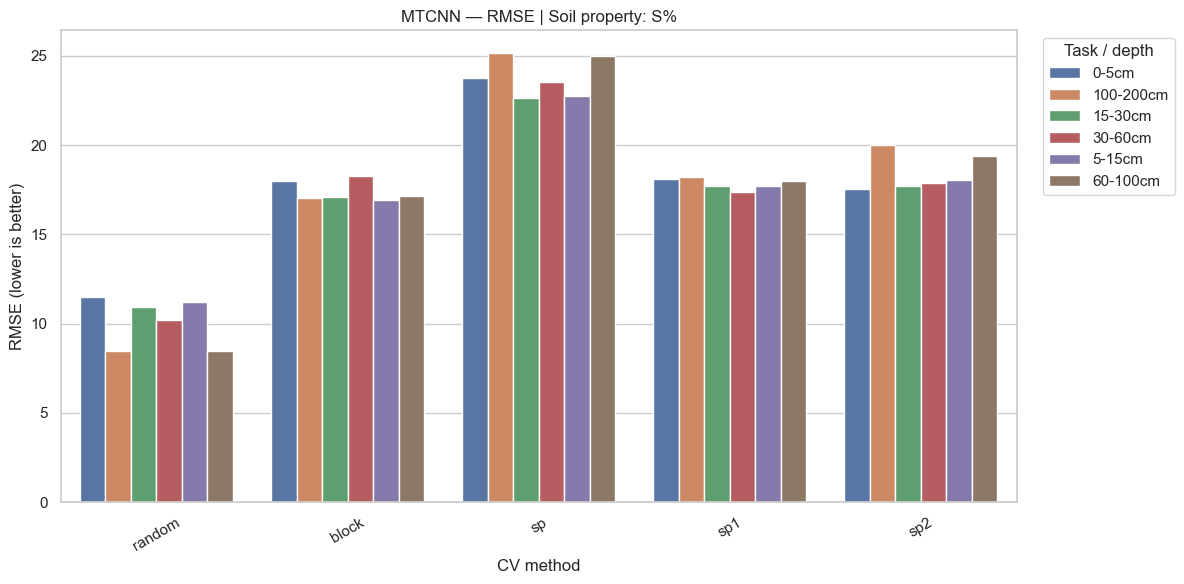

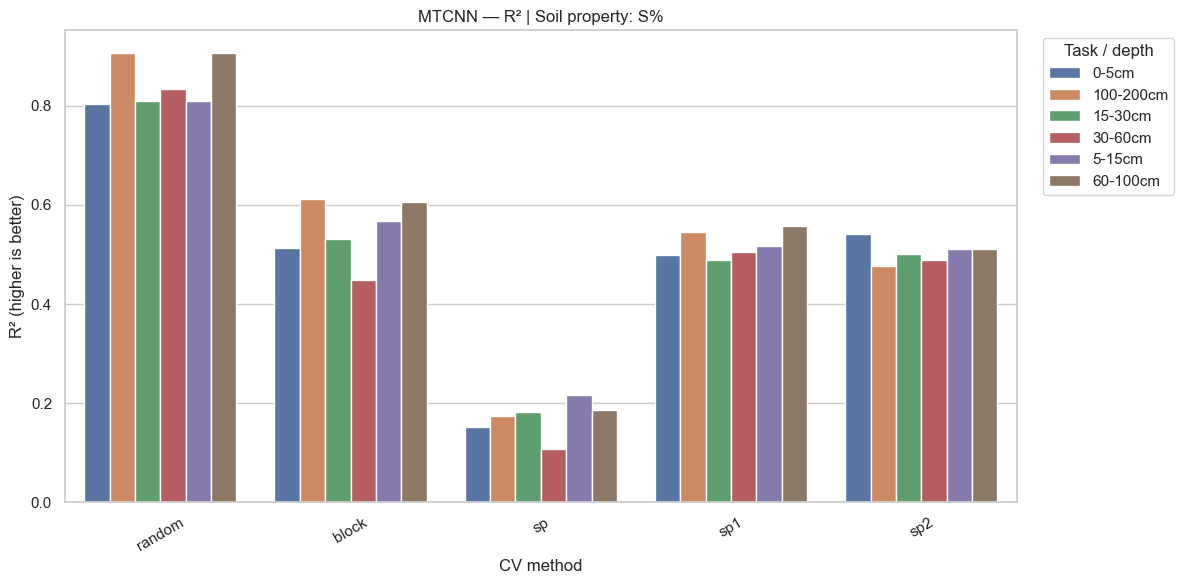

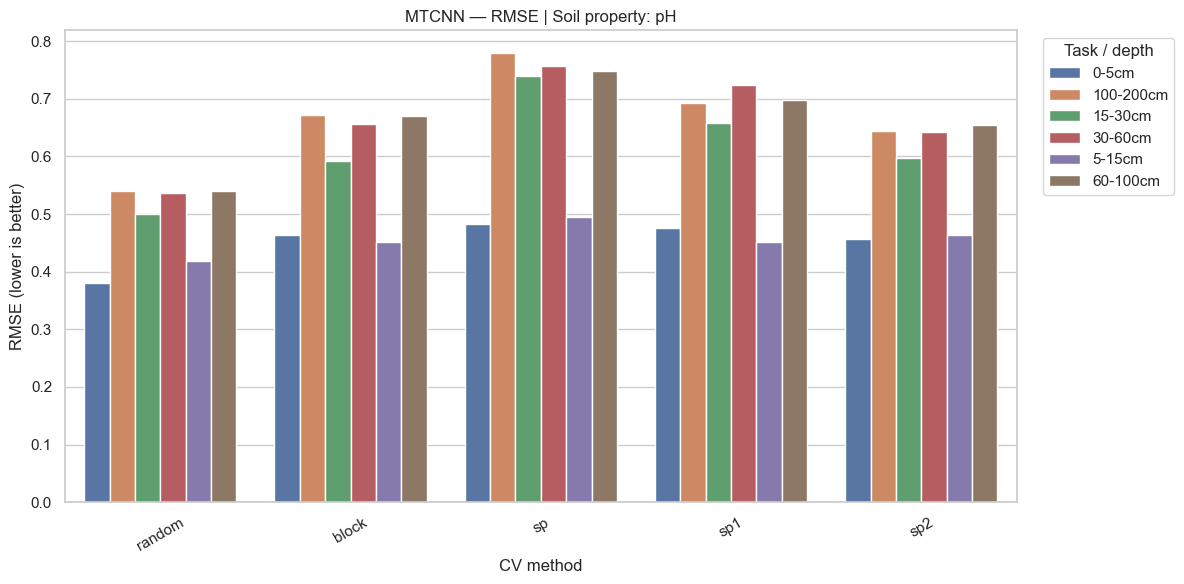

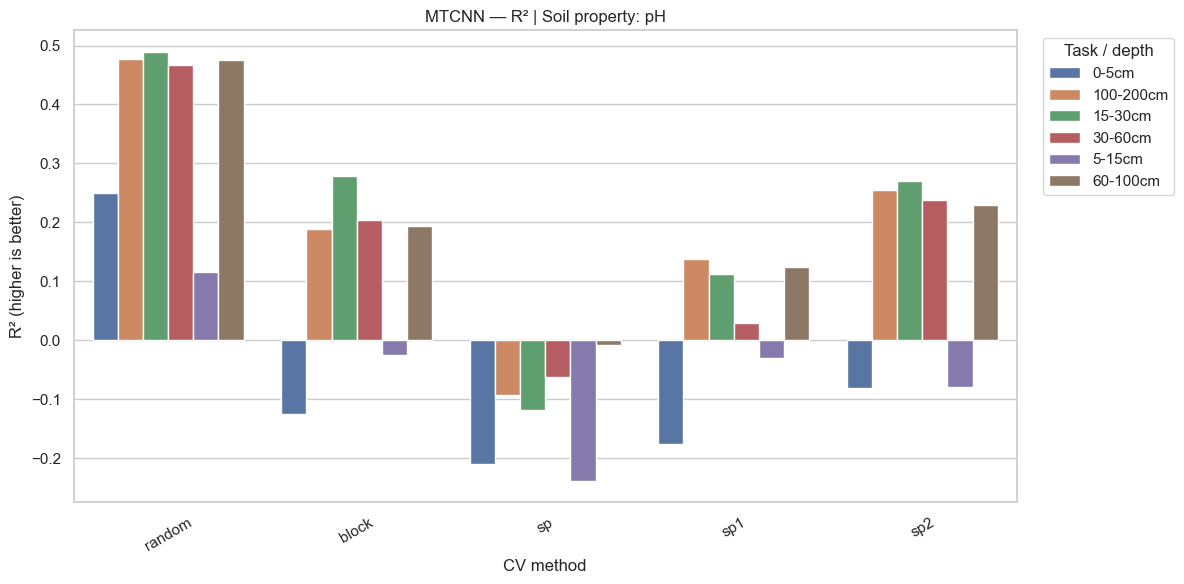

Charts and CSVs saved in: D:\DSM_MODULE\Training\cv_visualizations\Results_MTCNN_comparison


In [19]:

# ==========================================================
# 3. GROUPED CHARTS
#    X-axis = CV method
#    Legend = task/depth
#    Separate chart for each soil property
# ==========================================================

sns.set_theme(style="whitegrid")

# Optional ordering for consistent figures
preferred_cv_order = ["random", "SP2", "blockCV", "SP1", "SP"]

available_methods = mtcnn_avg_df["cv_method"].dropna().unique().tolist()

cv_order = (
    [m for m in preferred_cv_order if m in available_methods]
    + [m for m in sorted(available_methods) if m not in preferred_cv_order]
)

for prop in sorted(mtcnn_avg_df["soil_property"].dropna().unique()):
    plot_data = mtcnn_avg_df[
        mtcnn_avg_df["soil_property"] == prop
    ].copy()

    safe_prop = re.sub(r"[^A-Za-z0-9_-]+", "_", str(prop))

    for metric, ylabel, title in [
        ("rmse", "RMSE (lower is better)", "MTCNN — RMSE"),
        ("r2", "R² (higher is better)", "MTCNN — R²"),
    ]:
        if metric not in plot_data.columns:
            continue

        plot_data = plot_data.dropna(subset=[metric])

        if plot_data.empty:
            continue

        fig, ax = plt.subplots(figsize=(12, 6))

        sns.barplot(
            data=plot_data,
            x="cv_method",
            y=metric,
            hue="task",
            order=cv_order,
            errorbar=None,
            ax=ax,
        )

        ax.set_title(f"{title} | Soil property: {prop}")
        ax.set_xlabel("CV method")
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=30)
        ax.legend(
            title="Task / depth",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
        )

        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / f"{metric}_by_cv_method_{safe_prop}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

print(f"Charts and CSVs saved in: {OUTPUT_DIR.resolve()}")


## Threshold

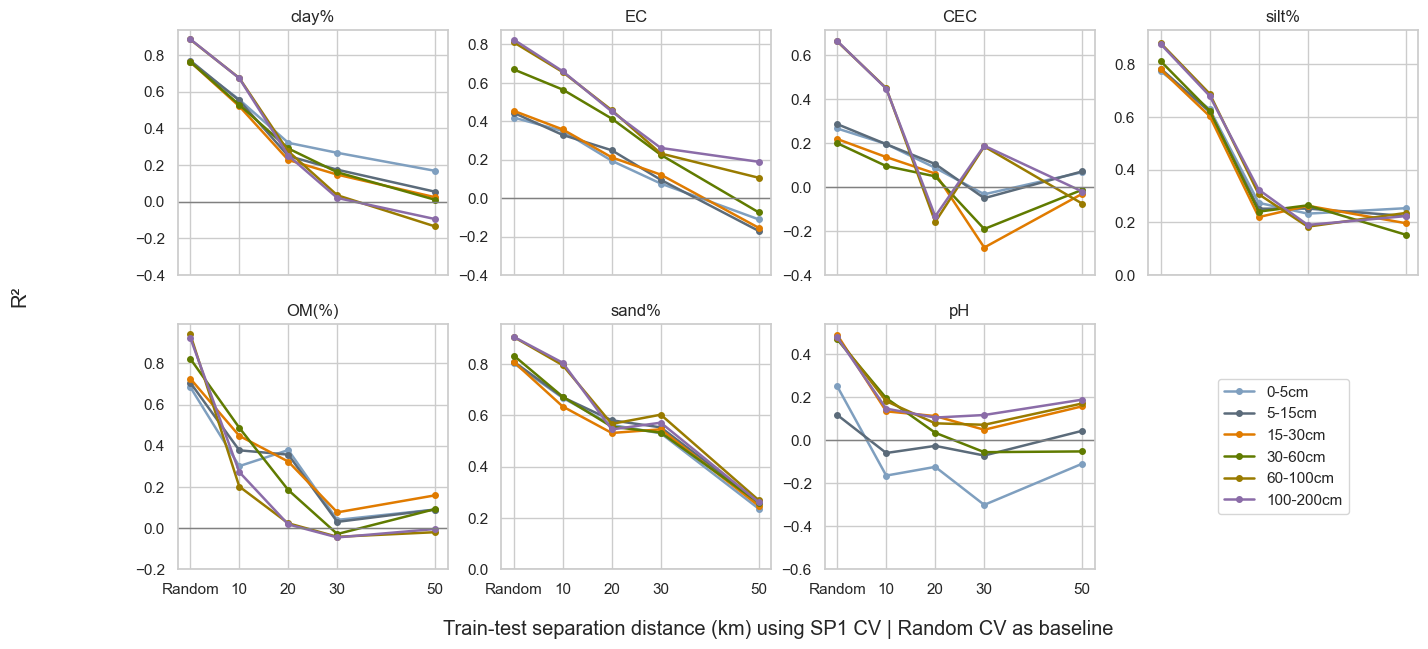

In [20]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math 

# --------------------------------------------------
# Configuration
# --------------------------------------------------
props = ["A%", "CE", "CEC", "L%", "OM(%)", "S%", "pH"]
title_property_map = {prop: prop for prop in props}  # Customize if needed
title_property_map['A%'] = 'clay%'
title_property_map['S%'] = 'sand%'
title_property_map['L%'] = 'silt%'
title_property_map['CE'] = 'EC'
title_property_map['OM'] = 'SOM'

# Replace these with the exact task labels in mtcnn_df["task"]
tasks = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

# Distinct colors for the six depth tasks
task_colors = {
    "0-5cm": "#7f9fbf",
    "5-15cm": "#5b6b7a",
    "15-30cm": "#e07b00",
    "30-60cm": "#607b00",
    "60-100cm": "#997b00",
    "100-200cm": "#8b6ca8",
}

# --------------------------------------------------
# Prepare the original threshold-level MTCNN results
# --------------------------------------------------
plot_df = mtcnn_df.copy()

plot_df["soil_property"] = (
    plot_df["soil_property"].astype(str).str.strip()
)
plot_df["task"] = plot_df["task"].astype(str).str.strip()
plot_df["cv_method"] = (
    plot_df["cv_method"].astype(str).str.strip().str.lower()
)
plot_df["r2"] = pd.to_numeric(plot_df["r2"], errors="coerce")

# Extract threshold in km.
# Supports values such as 50000, 100000, "50000 m", "10 km".
def threshold_to_km(value):
    if pd.isna(value) or str(value).strip() == "":
        return np.nan

    text = str(value).strip().lower()

    try:
        number = float(re.search(r"-?\d+\.?\d*", text).group())
    except (AttributeError, ValueError):
        return np.nan

    if "km" in text:
        return number
    if "m" in text:
        return number / 1000

    # Assumes bare numeric thresholds are in metres
    return number / 1000


plot_df["threshold_km"] = plot_df["threshold"].apply(threshold_to_km)

# --------------------------------------------------
# Plot: SP threshold effect, with Random as baseline
# --------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flat

for ax, p in zip(axes, props):
    property_values = []

    for task in tasks:
        s = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "sp1")
        ].copy()

        s["threshold_km"] = pd.to_numeric(s["threshold"], errors="coerce") / 1000
        s = s.dropna(subset=["threshold_km", "r2"]).sort_values("threshold_km")

        random_rows = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "random")
        ]

        if not random_rows.empty:
            random_r2 = random_rows["r2"].mean()
            property_values.append(random_r2)

        property_values.extend(s["r2"].dropna().tolist())

        x = [0] + s["threshold_km"].tolist()
        y = ([random_r2] if not random_rows.empty else [np.nan]) + s["r2"].tolist()

        ax.plot(
            x, y,
            "-o",
            color=task_colors[task],
            linewidth=1.8,
            markersize=4,
            label=task
        )

    ax.axhline(0, color="grey", linewidth=1)

    # Set a separate y-axis range for each property
    if property_values:
        ymin = min(property_values)
        ymax = max(property_values)

        # Round the lower limit down to a convenient interval
        lower_limit = math.floor((ymin - 0.1) * 5) / 5

        # Keep the upper limit at 1, or slightly above the maximum if needed
        upper_limit = min(1.0, max(ymax + 0.05, 0.2))

        ax.set_ylim(lower_limit, upper_limit)

    ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0, 10, 20, 30, 50])
    ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center")

fig.supxlabel("Train-test separation distance (km) using SP1 CV | Random CV as baseline")
fig.supylabel("R²")

fig.savefig(
    OUTPUT_DIR / "Threshold-effect-SP1CV-MTCNN.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

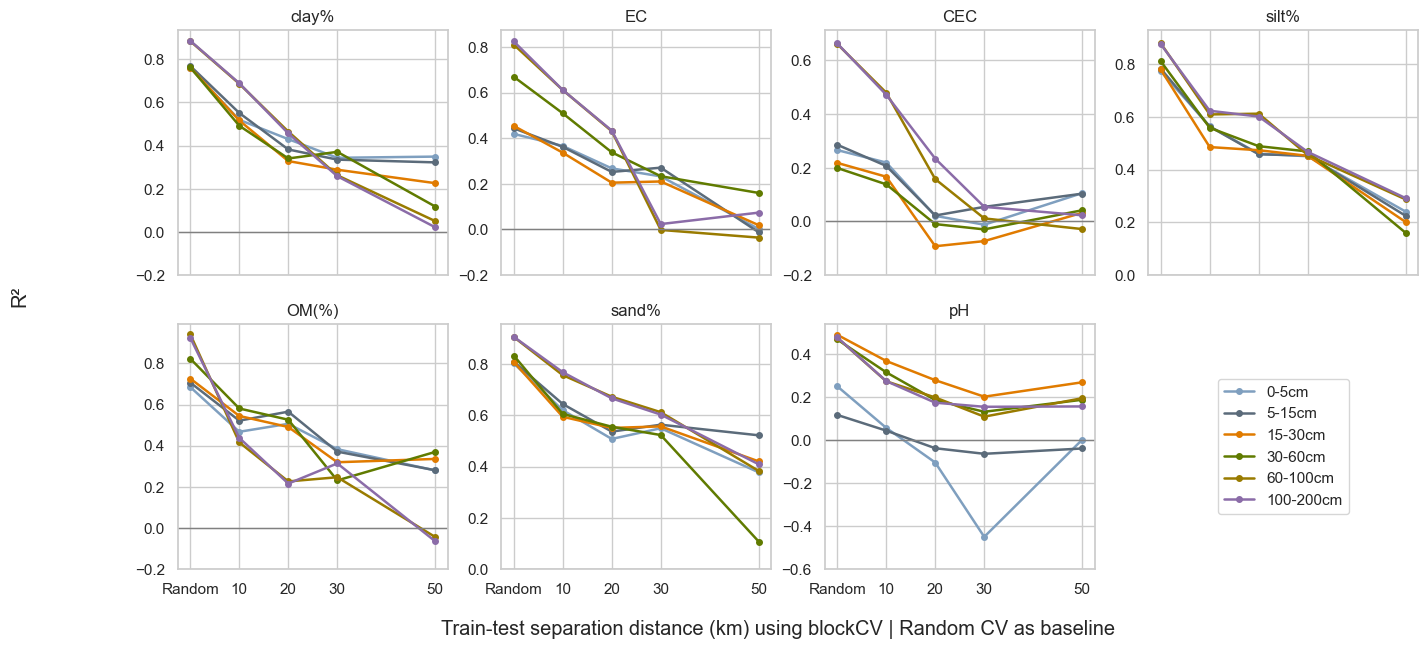

In [21]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math 

# --------------------------------------------------
# Configuration
# --------------------------------------------------
props = ["A%", "CE", "CEC", "L%", "OM(%)", "S%", "pH"]

# Replace these with the exact task labels in mtcnn_df["task"]
tasks = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

# Distinct colors for the six depth tasks
task_colors = {
    "0-5cm": "#7f9fbf",
    "5-15cm": "#5b6b7a",
    "15-30cm": "#e07b00",
    "30-60cm": "#607b00",
    "60-100cm": "#997b00",
    "100-200cm": "#8b6ca8",
}

# --------------------------------------------------
# Prepare the original threshold-level MTCNN results
# --------------------------------------------------
plot_df = mtcnn_df.copy()

plot_df["soil_property"] = (
    plot_df["soil_property"].astype(str).str.strip()
)
plot_df["task"] = plot_df["task"].astype(str).str.strip()
plot_df["cv_method"] = (
    plot_df["cv_method"].astype(str).str.strip().str.lower()
)
plot_df["r2"] = pd.to_numeric(plot_df["r2"], errors="coerce")

# Extract threshold in km.
# Supports values such as 50000, 100000, "50000 m", "10 km".
def threshold_to_km(value):
    if pd.isna(value) or str(value).strip() == "":
        return np.nan

    text = str(value).strip().lower()

    try:
        number = float(re.search(r"-?\d+\.?\d*", text).group())
    except (AttributeError, ValueError):
        return np.nan

    if "km" in text:
        return number
    if "m" in text:
        return number / 1000

    # Assumes bare numeric thresholds are in metres
    return number / 1000


plot_df["threshold_km"] = plot_df["threshold"].apply(threshold_to_km)

# --------------------------------------------------
# Plot: SP threshold effect, with Random as baseline
# --------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flat

for ax, p in zip(axes, props):
    property_values = []

    for task in tasks:
        s = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "block")
        ].copy()

        s["threshold_km"] = pd.to_numeric(s["threshold"], errors="coerce") / 1000
        s = s.dropna(subset=["threshold_km", "r2"]).sort_values("threshold_km")

        random_rows = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "random")
        ]

        if not random_rows.empty:
            random_r2 = random_rows["r2"].mean()
            property_values.append(random_r2)

        property_values.extend(s["r2"].dropna().tolist())

        x = [0] + s["threshold_km"].tolist()
        y = ([random_r2] if not random_rows.empty else [np.nan]) + s["r2"].tolist()

        ax.plot(
            x, y,
            "-o",
            color=task_colors[task],
            linewidth=1.8,
            markersize=4,
            label=task
        )

    ax.axhline(0, color="grey", linewidth=1)

    # Set a separate y-axis range for each property
    if property_values:
        ymin = min(property_values)
        ymax = max(property_values)

        # Round the lower limit down to a convenient interval
        lower_limit = math.floor((ymin - 0.1) * 5) / 5

        # Keep the upper limit at 1, or slightly above the maximum if needed
        upper_limit = min(1.0, max(ymax + 0.05, 0.2))

        ax.set_ylim(lower_limit, upper_limit)

    ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0, 10, 20, 30, 50])
    ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center")

fig.supxlabel("Train-test separation distance (km) using blockCV | Random CV as baseline")
fig.supylabel("R²")

fig.savefig(
    OUTPUT_DIR / "Threshold-effect-blockCV-MTCNN.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

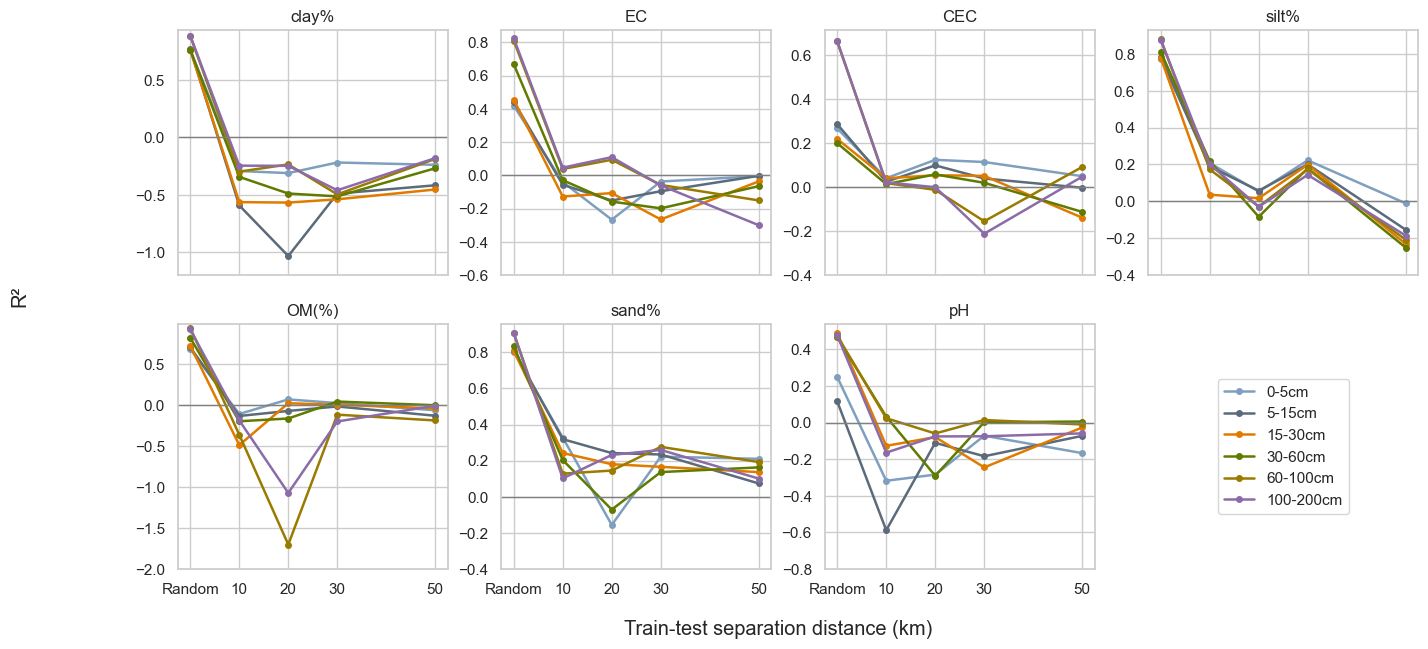

In [22]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math 

# --------------------------------------------------
# Configuration
# --------------------------------------------------
props = ["A%", "CE", "CEC", "L%", "OM(%)", "S%", "pH"]

# Replace these with the exact task labels in mtcnn_df["task"]
tasks = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

# Distinct colors for the six depth tasks
task_colors = {
    "0-5cm": "#7f9fbf",
    "5-15cm": "#5b6b7a",
    "15-30cm": "#e07b00",
    "30-60cm": "#607b00",
    "60-100cm": "#997b00",
    "100-200cm": "#8b6ca8",
}

# --------------------------------------------------
# Prepare the original threshold-level MTCNN results
# --------------------------------------------------
plot_df = mtcnn_df.copy()

plot_df["soil_property"] = (
    plot_df["soil_property"].astype(str).str.strip()
)
plot_df["task"] = plot_df["task"].astype(str).str.strip()
plot_df["cv_method"] = (
    plot_df["cv_method"].astype(str).str.strip().str.lower()
)
plot_df["r2"] = pd.to_numeric(plot_df["r2"], errors="coerce")

# Extract threshold in km.
# Supports values such as 50000, 100000, "50000 m", "10 km".
def threshold_to_km(value):
    if pd.isna(value) or str(value).strip() == "":
        return np.nan

    text = str(value).strip().lower()

    try:
        number = float(re.search(r"-?\d+\.?\d*", text).group())
    except (AttributeError, ValueError):
        return np.nan

    if "km" in text:
        return number
    if "m" in text:
        return number / 1000

    # Assumes bare numeric thresholds are in metres
    return number / 1000


plot_df["threshold_km"] = plot_df["threshold"].apply(threshold_to_km)

# --------------------------------------------------
# Plot: SP threshold effect, with Random as baseline
# --------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flat

for ax, p in zip(axes, props):
    property_values = []

    for task in tasks:
        s = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "sp")
        ].copy()

        s["threshold_km"] = pd.to_numeric(s["threshold"], errors="coerce") / 1000
        s = s.dropna(subset=["threshold_km", "r2"]).sort_values("threshold_km")

        random_rows = mtcnn_df[
            (mtcnn_df["soil_property"] == p) &
            (mtcnn_df["task"] == task) &
            (mtcnn_df["cv_method"].str.lower() == "random")
        ]

        if not random_rows.empty:
            random_r2 = random_rows["r2"].mean()
            property_values.append(random_r2)

        property_values.extend(s["r2"].dropna().tolist())

        x = [0] + s["threshold_km"].tolist()
        y = ([random_r2] if not random_rows.empty else [np.nan]) + s["r2"].tolist()

        ax.plot(
            x, y,
            "-o",
            color=task_colors[task],
            linewidth=1.8,
            markersize=4,
            label=task
        )

    ax.axhline(0, color="grey", linewidth=1)

    # Set a separate y-axis range for each property
    if property_values:
        ymin = min(property_values)
        ymax = max(property_values)

        # Round the lower limit down to a convenient interval
        lower_limit = math.floor((ymin - 0.1) * 5) / 5

        # Keep the upper limit at 1, or slightly above the maximum if needed
        upper_limit = min(1.0, max(ymax + 0.05, 0.2))

        ax.set_ylim(lower_limit, upper_limit)

    ax.set_title(title_property_map.get(p, p))
    ax.set_xticks([0, 10, 20, 30, 50])
    ax.set_xticklabels(["Random", 10, 20, 30, 50])

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center")

fig.supxlabel("Train-test separation distance (km)")
fig.supylabel("R²")

fig.savefig(
    OUTPUT_DIR / "Threshold-effect-SPCV-MTCNN.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 